# 03. Functional enrichment

Compare environmental association signals across genomic annotations and gene properties, and examine their relationships with population-genetic variation.


# 03. 功能富集

比较不同基因组注释和基因属性中的环境关联信号，并考察其与群体遗传变异的关系。


### Environment setup


### 环境设置


In [98]:
import warnings
warnings.filterwarnings('ignore')

import os
import socket
import sys
import json
import gzip
import pickle
from datetime import datetime
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm

%load_ext autoreload
%autoreload 2

with open('config/project.yaml') as handle:
    project_config = yaml.safe_load(handle)
project_dir = project_config['remote']['project_root']
if os.path.realpath(os.getcwd()) != os.path.realpath(project_dir):
    raise ValueError(f'Working directory {os.getcwd()} must match configured project root {project_dir}.')
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'
run_dir = f'{project_dir}/run'
enrich_dir = f'{results_dir}/enrichment'
os.makedirs(enrich_dir, exist_ok=True)
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)

print(f'Host: {socket.gethostname()}')
print(f'Working directory: {os.getcwd()}')
print(f'Python: {sys.executable}')
print(f"Environment prefix: {os.environ.get('CONDA_PREFIX', '<not set>')}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Host: rock01.local
Working directory: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum
Python: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base/bin/python
Environment prefix: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base


## 1. GEA enrichment

Evaluate four environmental variables: precipitation of the warmest quarter, growing season length, extractable aluminium and Striga HS score. Site comparisons use nominal Wald P values; gene comparisons use MAGMA gene P values.

For sites, compare the upper-tail association scores using the ratio of foreground and remaining-background 95th percentiles of −log10(P). Gene comparisons measure Jaccard overlap with the top 5% of associated genes. Chromosome-wise circular shifts provide permutation distributions and two-sided empirical P values.


## 1. GEA富集

分析四个环境变量：最暖季度降水量、生长季长度、可提取铝含量和Striga HS score。位点级对比使用nominal Wald P值，基因级对比使用MAGMA基因P值。

位点级分析比较上尾关联强度，以前景位点与背景其余位点的−log10(P)第95百分位数之比作为统计量。基因级分析计算目标集合与关联最强5%基因的Jaccard重叠。通过染色体内循环移位获得置换分布和双侧经验P值。


In [51]:
from src.plot import set_plot_style
from src.enrich import site_contrast_runner, plot_enrichment_section
from src.ld import prepare_ld_pairs, calculate_contrast_ld_overlap
set_plot_style()

### Association panels and shared parameters

Genome-wide variants have MAF ≥0.05; the CDS panel retains variants with MAF ≥0.01. Both use heterozygosity ≤0.05. Environmental scores are matched to variants or genes by ID. Use 1,000 permutations, and stratify genome-wide site comparisons into five MAF classes in addition to the combined panel.


### 关联数据与共同参数

全基因组变异采用MAF ≥0.05，CDS数据采用MAF ≥0.01，两者均要求杂合率 ≤0.05。按ID将环境关联分数与位点或基因对齐。采用1,000次置换；全基因组位点对比除合并分析外，还划分为五个MAF类别。


In [52]:
la_enrich_dir = f'{enrich_dir}/local_adaptation'
gwas_dir = f'{results_dir}/gwas'
os.makedirs(la_enrich_dir, exist_ok=True)
env_id_list = ['bio18', 'gsl', 'al', 'striga']
env_metadata_df = pd.read_csv(f'{source_dir}/envir_metadata.csv')
permutations = 1000
top_percent = 0.05
pool_num = project_config['resources']['interactive']['cores']
ld_window_size = 15000
min_r2 = 0.5
bin_width = 0.05
random_seed = 42
force_recompute = False

dataset_files = {
    'genome': f'{results_dir}/site_contexts.genome.maf0.05.h5',
    'cds': f'{results_dir}/site_contexts.cds.maf0.01.h5',
    'gene': f'{results_dir}/gene_contexts.h5',
}
vcf_files = {
    'genome': f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz',
    'cds': f'{results_dir}/landraces_cds_maf0.01_het0.05.vcf.gz',
}
with open(f'{project_dir}/config/contexts_settings.json') as handle:
    contexts_settings = json.load(handle)
with open(f'{project_dir}/config/contrasts_settings.json') as handle:
    contrasts_settings = json.load(handle)
stratify_label_map = [
    ['all', 'All MAF'], ['maf_0.05_0.1', '0.05–0.10'],
    ['maf_0.1_0.2', '0.10–0.20'], ['maf_0.2_0.3', '0.20–0.30'],
    ['maf_0.3_0.4', '0.30–0.40'], ['maf_0.4_0.5', '0.40–0.50'],
]


In [53]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Preparing association panels')
datasets = {}
for dataset, path in tqdm(dataset_files.items(), desc='Context panels'):
    data_df = pd.read_hdf(path, key='df')
    if data_df['ID'].isna().any() or not data_df['ID'].is_unique:
        raise ValueError(f'{dataset}: context IDs must be nonmissing and unique.')
    data_df = data_df.reset_index(drop=True)
    data_df[dataset] = True
    datasets[dataset] = data_df

for env_id in tqdm(env_id_list, desc='Environmental association scores'):
    for dataset, method, suffix, p_column in [
        ('genome', 'gemma', '', 'P_WALD'),
        ('cds', 'gemma', '_cds', 'P_WALD'),
        ('gene', 'magma', '', 'P_VALUE'),
    ]:
        name = f'{env_id}{suffix}'
        gwas_h5 = f'{gwas_dir}/{env_id}/{name}.{method}/{name}.{method}.gwas_df.h5'
        associations_df = pd.read_hdf(gwas_h5, key='df')[['ID', p_column]]
        associations_df[env_id] = -np.log10(associations_df[p_column])
        node_ids = datasets[dataset]['ID']
        datasets[dataset] = datasets[dataset].merge(
            associations_df[['ID', env_id]], on='ID', how='left', validate='one_to_one',
        )
        if not datasets[dataset]['ID'].equals(node_ids):
            raise ValueError(f'{dataset}: association merge changed the LD node order.')
for dataset in datasets:
    datasets[dataset] = datasets[dataset].reset_index(drop=True)
print(f'[{datetime.now():%H:%M:%S}] Association panels ready ({perf_counter() - stage_start:.1f}s)')
pd.DataFrame({dataset: {'rows': len(data_df), 'columns': len(data_df.columns)}
              for dataset, data_df in datasets.items()}).T


[00:57:57] Preparing association panels


Environmental association scores: 100%|██████████| 4/4 [01:52<00:00, 28.03s/it]

[00:59:55] Association panels ready (118.4s)


,rows,columns
genome,6452577,48
cds,386925,21
gene,31819,23


### Linkage between foreground and background signals

Calculate LD within 15 kb using the corresponding QC genotypes. Rank foreground and remaining-background sites separately by association strength and compare matching 5%-wide rank bins. Linkage summarizes the maximum opposite-group r² per site, scaled above r² =0.5, with a shuffled-score reference. LD indicates linked signals rather than a shared causal variant.


### 前景与背景信号之间的连锁联系

使用对应的质控基因型计算15 kb内的LD。前景与背景其余位点分别按关联强度排序，比较对应的5%宽度排名区间。连锁指标汇总各位点与另一组位点间的最大r²，并在r² =0.5以上缩放，以打乱关联分数作为参照。LD反映信号之间的连锁联系，不能确定共享因果位点。


In [54]:
stage_start = perf_counter()
ld_pairs_files = {
    dataset: f'{la_enrich_dir}/ld_pairs.{dataset}.by_index.win{ld_window_size}.r2{min_r2}.h5'
    for dataset in vcf_files
}
ld_dict = {}
for dataset, vcf_file in tqdm(vcf_files.items(), desc='LD panels'):
    legacy_pairs_h5 = f'{la_enrich_dir}/ld_pairs.{dataset}.by_id.win{ld_window_size}.r2{min_r2}.h5'
    ld_dict[dataset] = prepare_ld_pairs(
        datasets[dataset][['ID', 'CHROM', 'POS']], vcf_file, ld_pairs_files[dataset],
        legacy_pairs_h5=legacy_pairs_h5, ld_window_size=ld_window_size,
        min_r2=min_r2, pool_num=pool_num, force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] LD panels ready ({perf_counter() - stage_start:.1f}s)')


LD panels:   0%|          | 0/2 [00:00<?, ?it/s]

[01:00:01] Reading integer LD pairs: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ld_pairs.genome.by_index.win15000.r20.5.h5


LD panels:  50%|█████     | 1/2 [00:11<00:11, 11.55s/it]

[01:00:07] Reading integer LD pairs: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ld_pairs.cds.by_index.win15000.r20.5.h5


LD panels: 100%|██████████| 2/2 [00:11<00:00,  5.92s/it]

[01:00:08] LD panels ready (11.9s)


### 1.1 Genomic compartments

Compare Genic, TE and Other intergenic sites using the genome-wide background, and Distal TEs and Proximal TEs within their respective Distal and Proximal backgrounds. Genic includes gene bodies and 2 kb flanks. Proximal includes gene bodies and 5 kb flanks; Distal lies outside that range. Other intergenic excludes both Genic and TE regions. In each comparison, the background defines the tested population and the foreground is compared with its remaining sites.


### 1.1 基因组区室

以全基因组为背景比较Genic、TE和Other intergenic；Distal TEs和Proximal TEs分别在Distal与Proximal背景中比较。Genic包括基因本体及两侧各2 kb；Proximal包括基因本体及两侧各5 kb，Distal为该范围之外的区域。Other intergenic排除Genic与TE区域。各对比以背景定义受检集合，将前景与该背景中的其余位点比较。


In [55]:
contrast_label_map = [
    ('genic_2kb_vs_genome', 'Genic vs. Genome'),
    ('TE_vs_genome', 'TE vs. Genome'),
    ('proximal_TE_vs_proximal', 'Proximal TEs vs. Proximal'),
    ('distal_TE_vs_distal', 'Distal TEs vs. Distal'),
    ('other_intergenic_vs_genome', 'Other intergenic vs. Genome'),
]
compartment_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in contrast_label_map
}
figure_prefix = f'{la_enrich_dir}/genomic_compartments.enrichment_and_overlap'

In [56]:
stage_start = perf_counter()
for contrast_id, label in tqdm(contrast_label_map, desc='Genomic compartments'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Compartment results ready ({perf_counter() - stage_start:.1f}s)')


Genomic compartments: 100%|██████████| 5/5 [00:00<00:00, 12.59it/s]

Enrichment results already exist for contrast genic_2kb_vs_genome, skipping.
LD overlap results already exist for contrast genic_2kb_vs_genome. Skipping calculation.
Enrichment results already exist for contrast TE_vs_genome, skipping.
LD overlap results already exist for contrast TE_vs_genome. Skipping calculation.
Enrichment results already exist for contrast proximal_TE_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_TE_vs_proximal. Skipping calculation.
Enrichment results already exist for contrast distal_TE_vs_distal, skipping.
LD overlap results already exist for contrast distal_TE_vs_distal. Skipping calculation.
Enrichment results already exist for contrast other_intergenic_vs_genome, skipping.
LD overlap results already exist for contrast other_intergenic_vs_genome. Skipping calculation.
[01:00:09] Compartment results ready (0.4s)


#### Display genomic-compartment enrichment

Each block contains four environmental panels. Upper panels show observed and permutation enrichment Z scores for all variants and each MAF class; stars mark two-sided P <0.05. Lower panels show foreground–background LD linkage by GEA-rank bin and its shuffled-score reference. Read enrichment direction relative to the permutation distribution; the raw association-score ratios are retained in the exported data.


#### 展示基因组区室富集

每组对比包含四个环境变量面板。上半部分展示全部变异及各MAF类别的观测和置换富集Z-score，星号表示双侧P <0.05。下半部分展示各GEA排名区间的前景–背景LD联系及打乱分数后的参照。结合置换分布判断富集方向，原始关联强度比值保留在导出数据中。


2026-10-13 01:00:09 Plotting 5 enrichment contrasts


Enrichment panels: 100%|██████████| 5/5 [00:01<00:00,  3.65it/s]


2026-10-13 01:00:21 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap


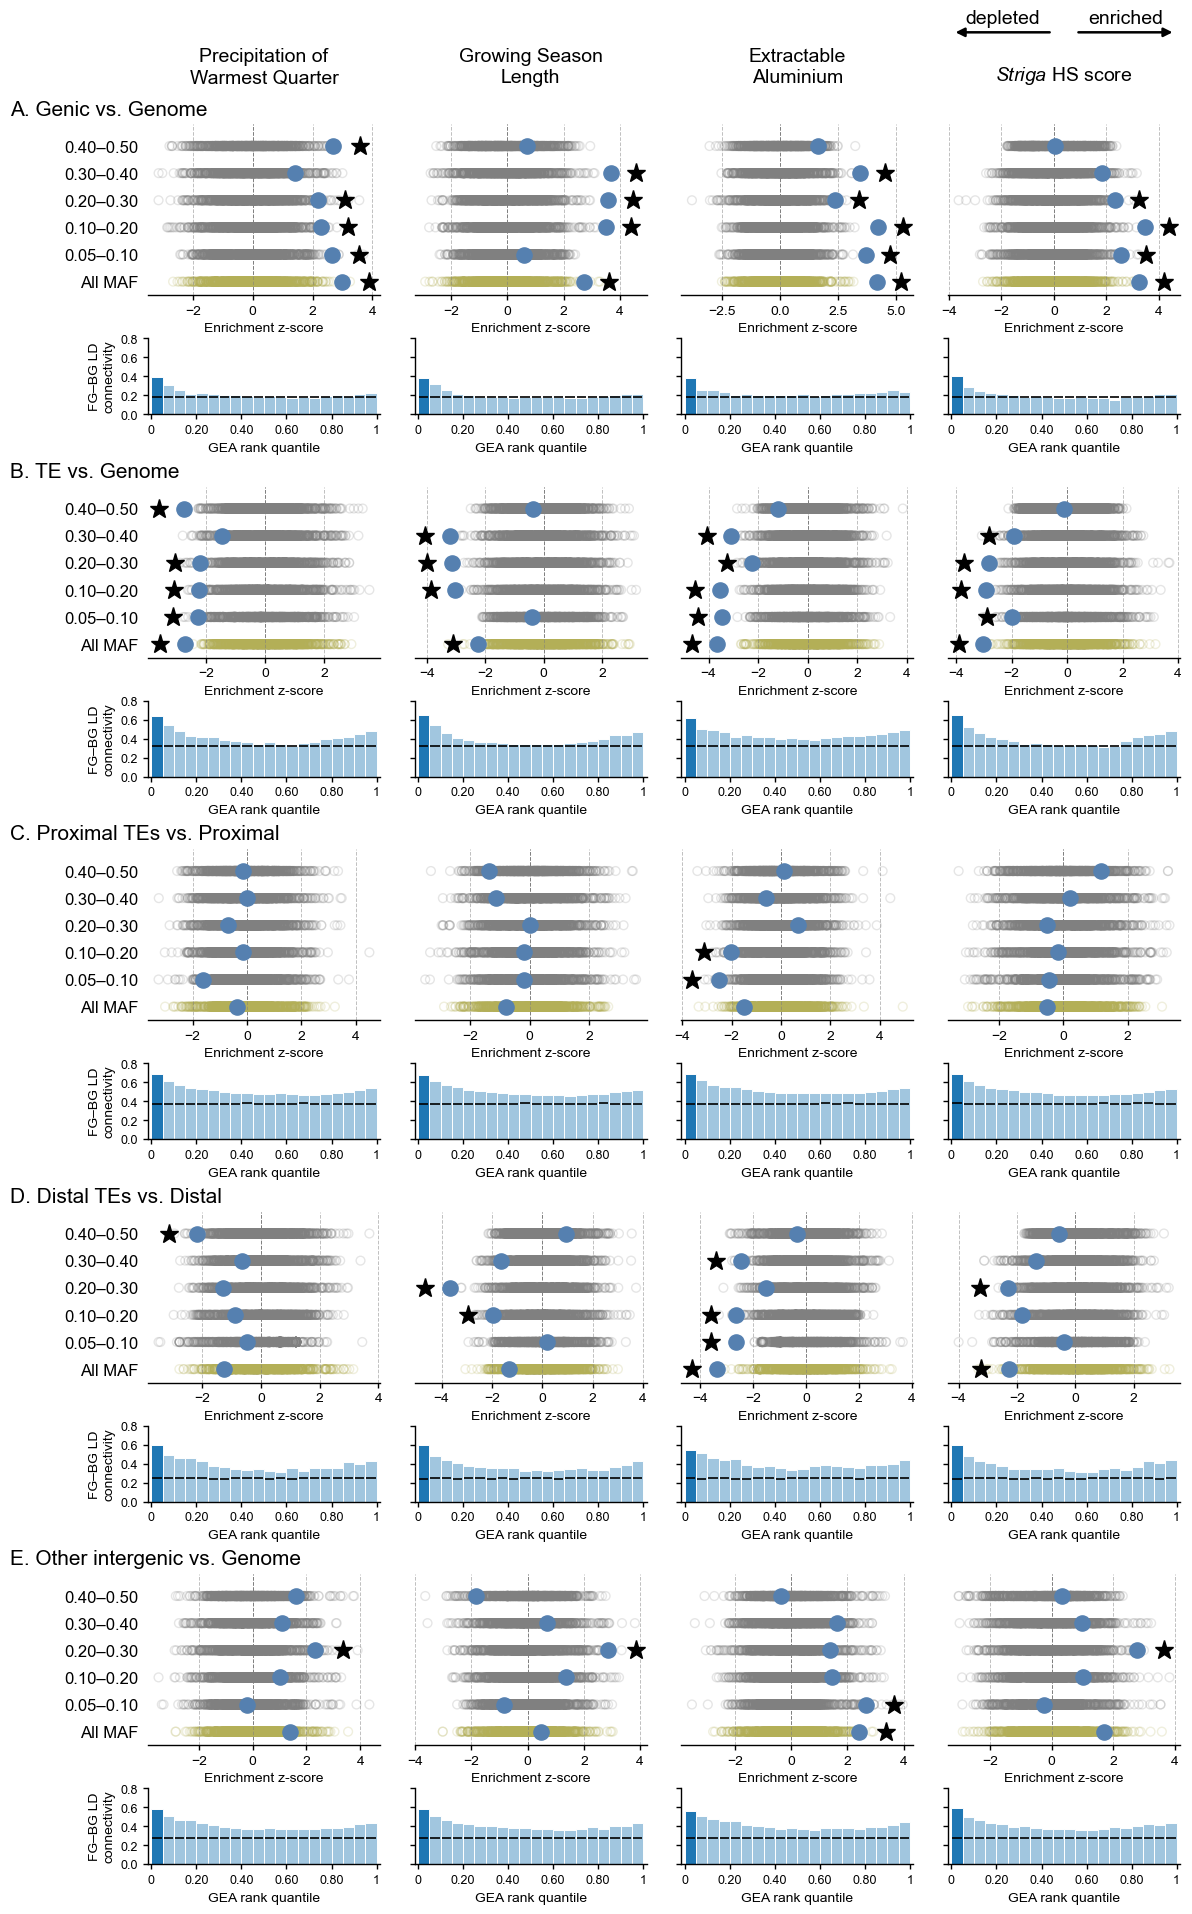

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap.ld_overlap.csv.gz'}


In [57]:
compartment_plot = plot_enrichment_section(
    compartment_result_files, contrast_label_map, env_id_list,
    env_metadata_df, stratify_label_map, figure_prefix,
    figsize=(12, 19), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(compartment_plot['files'])


### 1.2 Gene structure

Compare GEA signals in upstream 2 kb, 5′ UTR, CDS, introns, 3′ UTR and downstream 2 kb regions. Gene structures follow the longest annotated transcript; upstream and downstream regions follow gene orientation. An annotation can overlap another gene's structure, so these categories need not be mutually exclusive.

Use two backgrounds: Genic, comprising gene bodies and 2 kb flanks, and Genome, comprising all genome-wide QC variants with MAF ≥0.05. Each structural category is compared with the remaining sites in its background. Both comparisons use the same genome-wide panel, including CDS sites; the lower-MAF CDS panel is not used here.


### 1.2 基因结构

比较上游2 kb、5′ UTR、CDS、内含子、3′ UTR和下游2 kb区域中的GEA信号。基因结构依据最长的注释转录本，上下游区域按基因方向定义。不同基因的结构注释可以重叠，因此这些类别不一定互斥。

使用两种背景：Genic包括基因本体及两侧各2 kb，Genome包括全部MAF ≥0.05的全基因组质控变异。各结构类别分别与相应背景中的其余位点比较。两组均使用同一套全基因组数据，包括其中的CDS位点；此处不使用较低MAF阈值的CDS数据。


In [58]:
structure_labels = [
    ('upstream_2kb', 'Upstream 2 kb'),
    ('five_prime_UTR', '5′ UTR'),
    ('CDS', 'CDS'),
    ('intron', 'Intron'),
    ('three_prime_UTR', '3′ UTR'),
    ('downstream_2kb', 'Downstream 2 kb'),
]
structure_contrast_labels = {
    background: [(f'{context_id}_vs_{background}', f'{label} vs. {background.capitalize()}')
                 for context_id, label in structure_labels]
    for background in ['genic', 'genome']
}
structure_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for labels in structure_contrast_labels.values()
    for contrast_id, _ in labels
}
structure_figure_prefix = f'{la_enrich_dir}/gene_structure'
plot_params = dict(
    figsize=(12, 22.8), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)


#### 1.2.1 Genic background

Compare each structural category with other Genic sites to assess differences within gene-associated regions. The Genic background includes gene bodies and 2 kb flanks on both sides.


#### 1.2.1 Genic背景

将各结构类别与Genic中的其余位点比较，考察基因相关区域内部的关联强度差异。Genic背景包括基因本体及两侧各2 kb。


In [59]:
stage_start = perf_counter()
for contrast_id, label in tqdm(structure_contrast_labels['genic'], desc='Gene structure: Genic'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Genic comparisons ready ({perf_counter() - stage_start:.1f}s)')


Gene structure: Genic: 100%|██████████| 6/6 [00:00<00:00, 91.48it/s]

Enrichment results already exist for contrast upstream_2kb_vs_genic, skipping.
LD overlap results already exist for contrast upstream_2kb_vs_genic. Skipping calculation.
Enrichment results already exist for contrast five_prime_UTR_vs_genic, skipping.
LD overlap results already exist for contrast five_prime_UTR_vs_genic. Skipping calculation.
Enrichment results already exist for contrast CDS_vs_genic, skipping.
LD overlap results already exist for contrast CDS_vs_genic. Skipping calculation.
Enrichment results already exist for contrast intron_vs_genic, skipping.
LD overlap results already exist for contrast intron_vs_genic. Skipping calculation.
Enrichment results already exist for contrast three_prime_UTR_vs_genic, skipping.
LD overlap results already exist for contrast three_prime_UTR_vs_genic. Skipping calculation.
Enrichment results already exist for contrast downstream_2kb_vs_genic, skipping.
LD overlap results already exist for contrast downstream_2kb_vs_genic. Skipping calculati

##### Display structural enrichment within the Genic background

Six blocks show the structural categories, with environmental column titles appearing once at the top. Upper panels compare observed and permutation enrichment Z scores across MAF classes; stars mark two-sided P <0.05. Lower panels show cross-group LD linkage by GEA-rank bin, with a shuffled-score reference.


##### 展示Genic背景中的基因结构富集

六组面板分别展示各结构类别，环境变量列标题仅在整图顶部出现。上半部分比较各MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间的跨组LD联系及打乱分数后的参照。


2026-10-13 01:00:29 Plotting 6 enrichment contrasts


Enrichment panels: 100%|██████████| 6/6 [00:02<00:00,  2.36it/s]


2026-10-13 01:00:46 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap


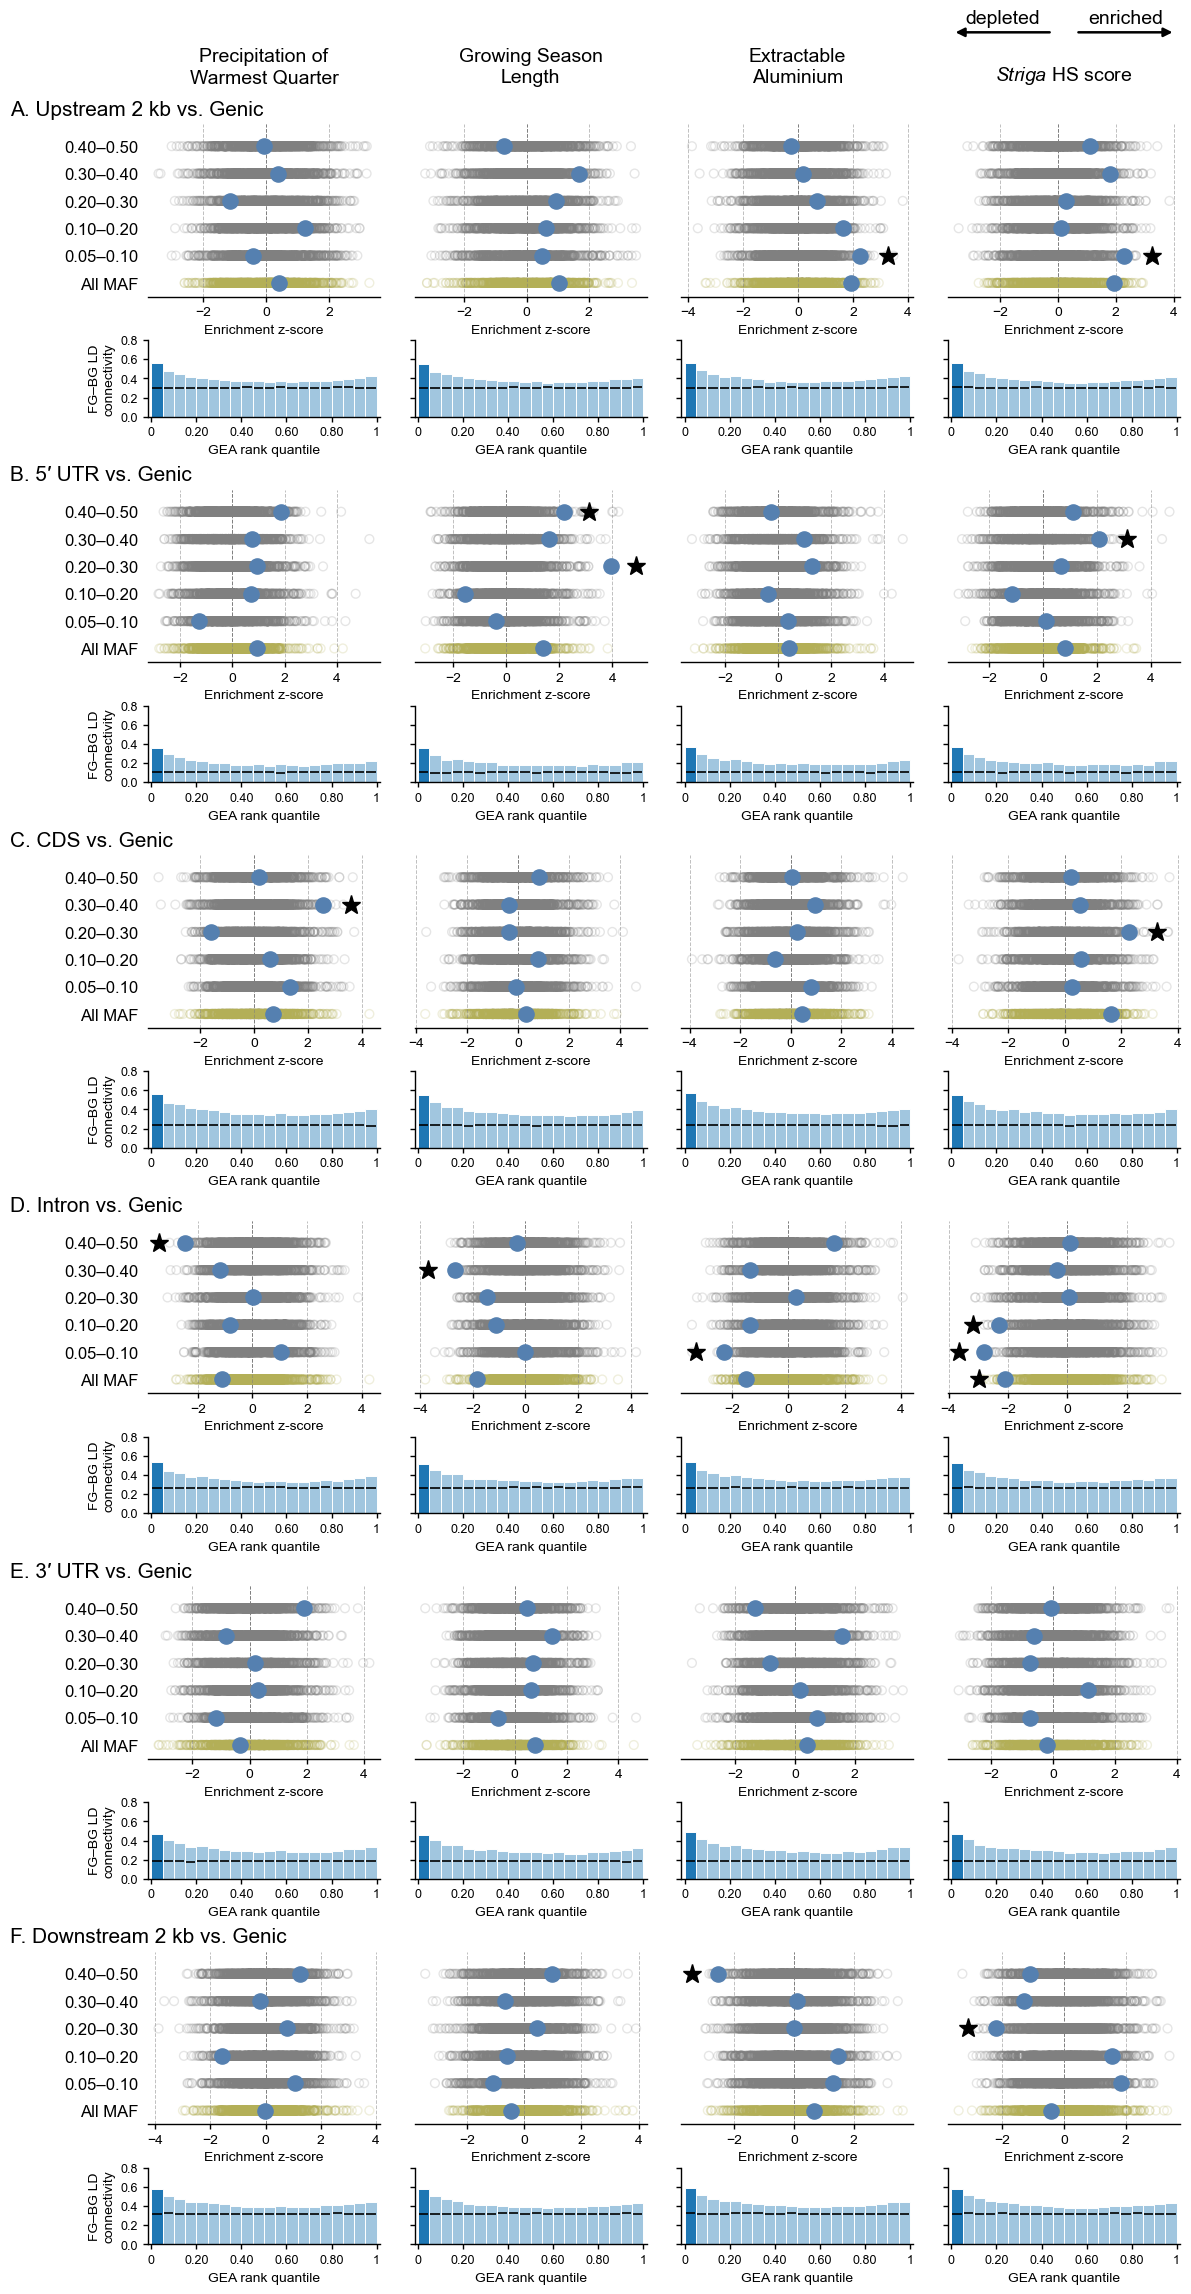

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap.ld_overlap.csv.gz'}


In [60]:
genic_structure_plot = plot_enrichment_section(
    structure_result_files, structure_contrast_labels['genic'], env_id_list,
    env_metadata_df, stratify_label_map,
    f'{structure_figure_prefix}.genic.enrichment_and_overlap', **plot_params,
)
plt.show()
print(genic_structure_plot['files'])


#### 1.2.2 Genome background

Compare the same structural categories with the remaining genome-wide sites to assess their association enrichment relative to the broader genomic background.


#### 1.2.2 Genome背景

将相同结构类别与全基因组中的其余位点比较，考察其相对于更广泛基因组背景的关联富集。


In [61]:
stage_start = perf_counter()
for contrast_id, label in tqdm(structure_contrast_labels['genome'], desc='Gene structure: Genome'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Genome comparisons ready ({perf_counter() - stage_start:.1f}s)')


Gene structure: Genome: 100%|██████████| 6/6 [00:00<00:00, 88.61it/s]

Enrichment results already exist for contrast upstream_2kb_vs_genome, skipping.
LD overlap results already exist for contrast upstream_2kb_vs_genome. Skipping calculation.
Enrichment results already exist for contrast five_prime_UTR_vs_genome, skipping.
LD overlap results already exist for contrast five_prime_UTR_vs_genome. Skipping calculation.
Enrichment results already exist for contrast CDS_vs_genome, skipping.
LD overlap results already exist for contrast CDS_vs_genome. Skipping calculation.
Enrichment results already exist for contrast intron_vs_genome, skipping.
LD overlap results already exist for contrast intron_vs_genome. Skipping calculation.
Enrichment results already exist for contrast three_prime_UTR_vs_genome, skipping.
LD overlap results already exist for contrast three_prime_UTR_vs_genome. Skipping calculation.
Enrichment results already exist for contrast downstream_2kb_vs_genome, skipping.
LD overlap results already exist for contrast downstream_2kb_vs_genome. Skippi

##### Display structural enrichment within the Genome background

Six blocks show the structural categories, with environmental column titles appearing once at the top. Upper panels compare observed and permutation enrichment Z scores across MAF classes; stars mark two-sided P <0.05. Lower panels show cross-group LD linkage by GEA-rank bin, with a shuffled-score reference.


##### 展示Genome背景中的基因结构富集

六组面板分别展示各结构类别，环境变量列标题仅在整图顶部出现。上半部分比较各MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间的跨组LD联系及打乱分数后的参照。


2026-10-13 01:00:54 Plotting 6 enrichment contrasts


Enrichment panels: 100%|██████████| 6/6 [00:01<00:00,  3.67it/s]


2026-10-13 01:01:09 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap


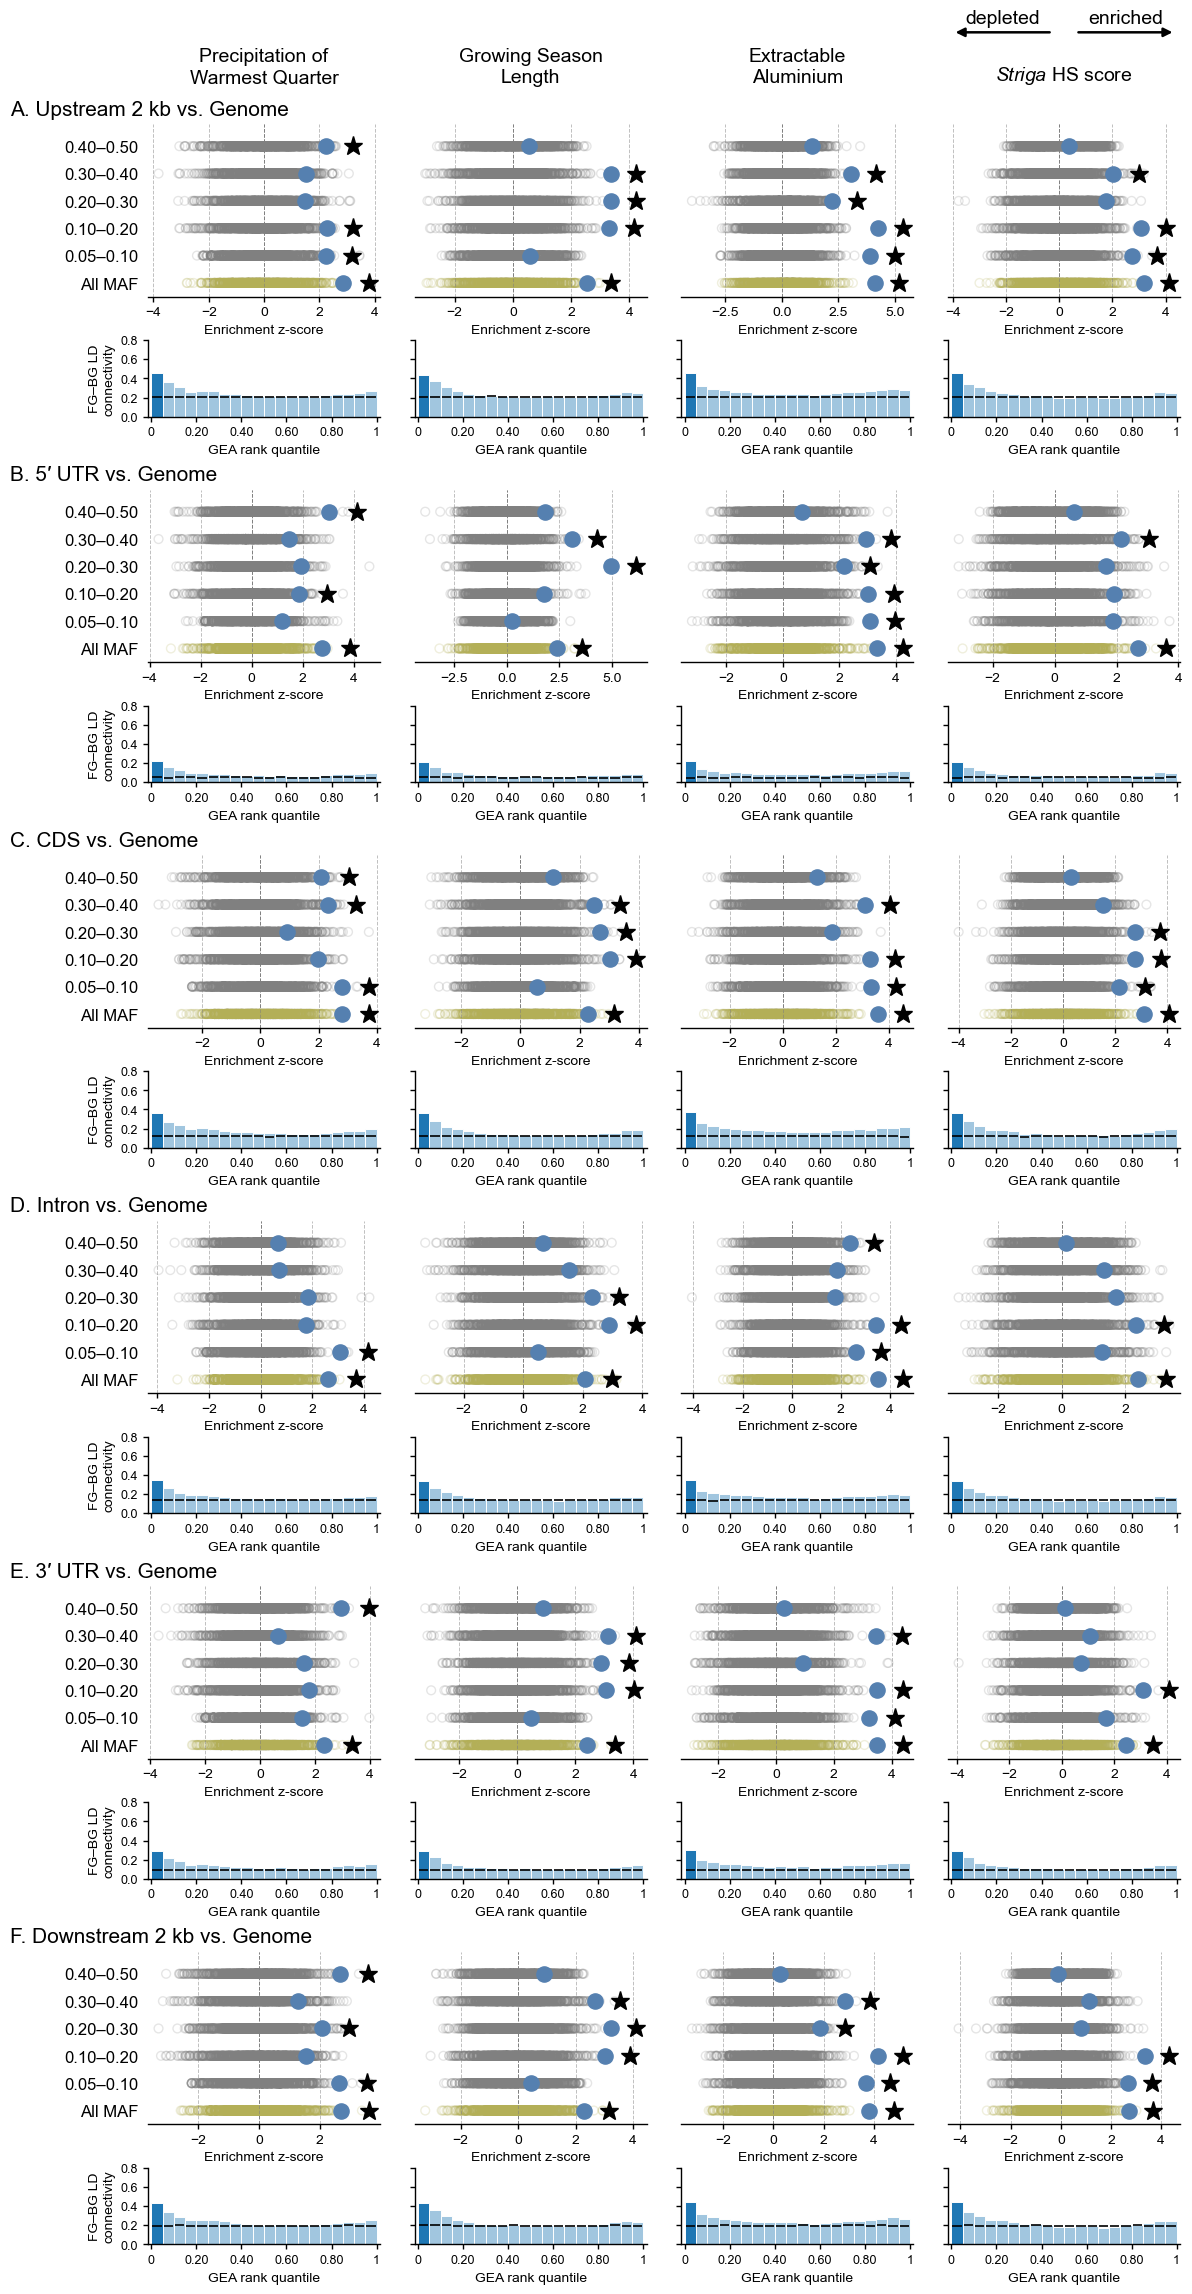

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap.ld_overlap.csv.gz'}


In [62]:
genome_structure_plot = plot_enrichment_section(
    structure_result_files, structure_contrast_labels['genome'], env_id_list,
    env_metadata_df, stratify_label_map,
    f'{structure_figure_prefix}.genome.enrichment_and_overlap', **plot_params,
)
plt.show()
print(genome_structure_plot['files'])


### 1.3 Coding mutations

Compare GEA signals among missense, synonymous and putative loss-of-function (LoF) variants using SnpEff consequence annotations. These are predicted effects; putative LoF does not establish experimentally confirmed loss of function. Use the CDS panel with MAF ≥0.01 and heterozygosity ≤0.05, with environmental associations calculated for that panel.

First compare each consequence class with the remaining CDS variants. Then compare putative LoF variants in two lower-frequency classes to examine differences within the LoF set.


### 1.3 编码变异

依据SnpEff后果注释，比较错义、同义和候选功能缺失（putative LoF）变异中的GEA信号。这些类别描述预测后果；候选LoF不能等同于经实验确认的功能缺失。使用MAF ≥0.01、杂合率 ≤0.05的CDS数据及其对应的环境关联结果。

先将各后果类别与其余CDS变异比较，再比较两个较低频率类别中的候选LoF变异，考察LoF集合内部的差异。


In [63]:
coding_contrast_labels = [
    ('missense_vs_CDS', 'Missense vs. CDS'),
    ('synonymous_vs_CDS', 'Synonymous vs. CDS'),
    ('putative_LoF_vs_CDS', 'Putative LoF vs. CDS'),
]
lof_contrast_id = 'putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05'
lof_contrast_labels = [(lof_contrast_id, 'Putative LoF: MAF 0.01–0.03 vs. 0.03–0.05')]
coding_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in coding_contrast_labels + lof_contrast_labels
}
cds_stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01–0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03–0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05–0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10–0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20–0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30–0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40–0.50'],
]
coding_figure_prefix = f'{la_enrich_dir}/coding_mutations'
plot_params = dict(
    figsize=(12, 13.2), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35, height_ratios=(3, 1)),
    letter_labels=True, env_titles_first_only=True,
)


#### 1.3.1 Coding consequences within the CDS background

Compare missense, synonymous and putative LoF variants with the remaining CDS sites. Analyze all retained sites and seven MAF classes, including the rarer 0.01–0.03 and 0.03–0.05 classes. This describes whether consequence classes differ in upper-tail GEA strength relative to the same coding background.


#### 1.3.1 CDS背景中的编码后果

将错义、同义及候选LoF变异与其余CDS位点比较。分别分析全部保留位点和七个MAF类别，包括较稀有的0.01–0.03和0.03–0.05类别，考察不同后果类别相对于同一编码背景的上尾GEA关联强度。


In [64]:
stage_start = perf_counter()
for contrast_id, label in tqdm(coding_contrast_labels, desc='Coding consequences'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Coding-consequence results ready ({perf_counter() - stage_start:.1f}s)')


Coding consequences: 100%|██████████| 3/3 [00:00<00:00, 68.88it/s]

Enrichment results already exist for contrast missense_vs_CDS, skipping.
LD overlap results already exist for contrast missense_vs_CDS. Skipping calculation.
Enrichment results already exist for contrast synonymous_vs_CDS, skipping.
LD overlap results already exist for contrast synonymous_vs_CDS. Skipping calculation.
Enrichment results already exist for contrast putative_LoF_vs_CDS, skipping.
LD overlap results already exist for contrast putative_LoF_vs_CDS. Skipping calculation.
[01:01:17] Coding-consequence results ready (0.0s)


##### Display coding-consequence enrichment

Three lettered blocks share four environmental column titles at the top. Upper panels show observed and permutation enrichment Z scores across MAF classes; stars mark two-sided P <0.05. Lower panels show cross-group LD linkage by GEA-rank bin and its shuffled-score reference.


##### 展示编码后果富集

三组字母编号面板共用整图顶部的四个环境变量列标题。上半部分展示各MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间的跨组LD联系及打乱分数后的参照。


2026-10-13 01:01:18 Plotting 3 enrichment contrasts


Enrichment panels: 100%|██████████| 3/3 [00:00<00:00,  3.28it/s]


2026-10-13 01:01:27 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap


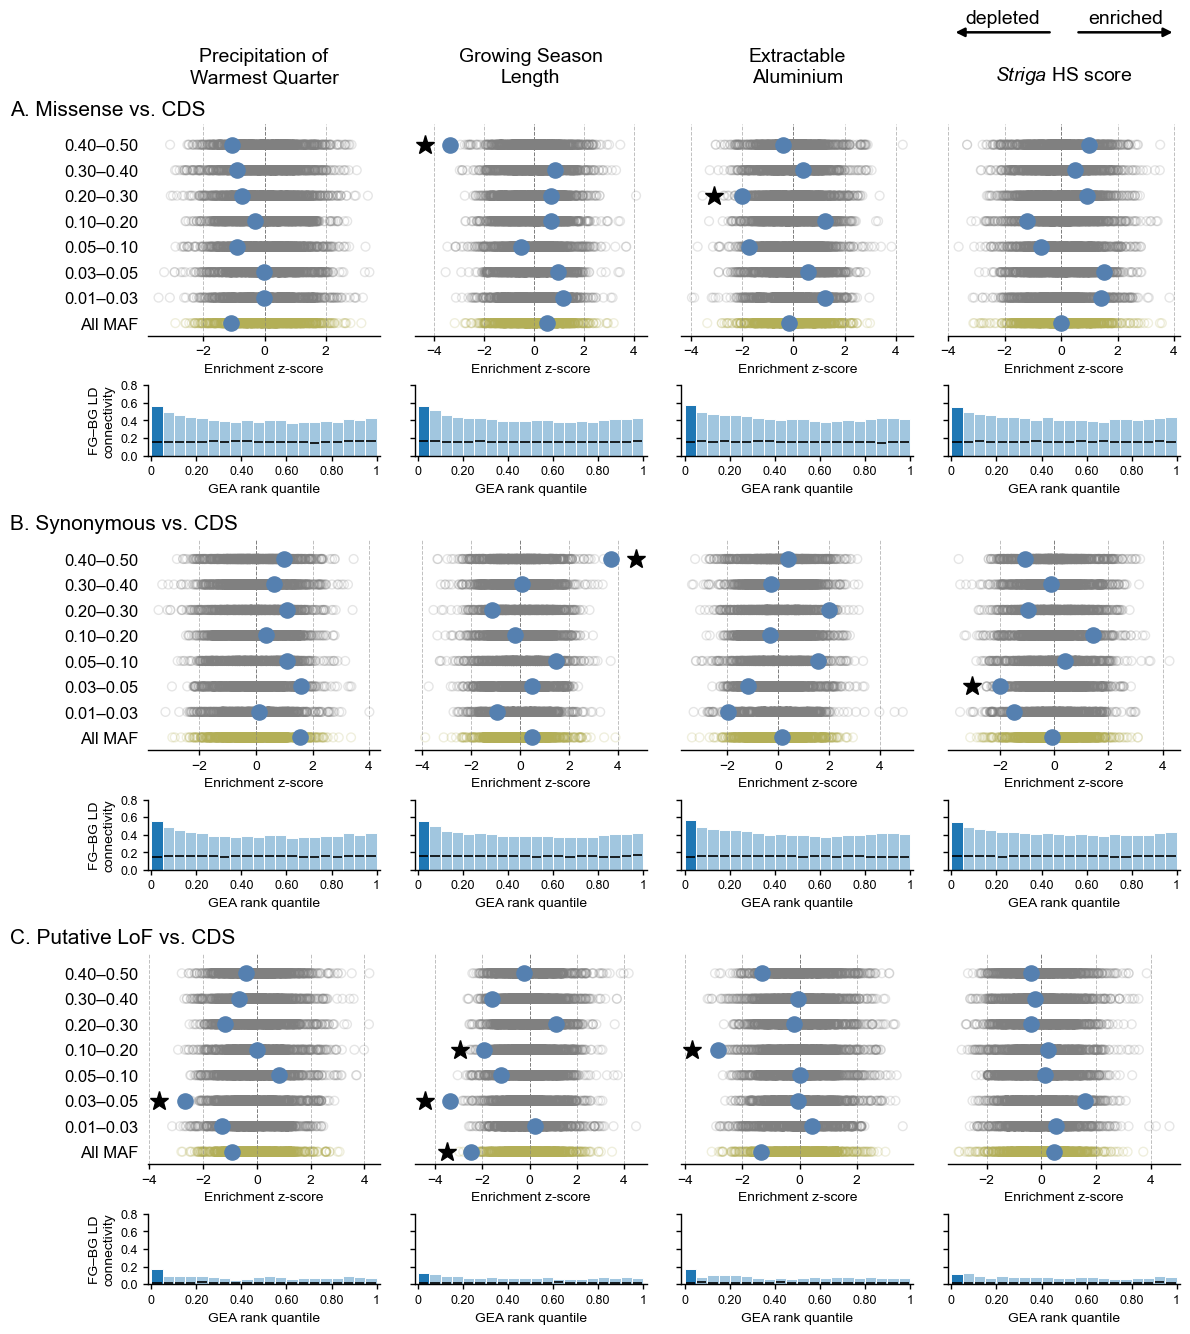

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap.ld_overlap.csv.gz'}


In [65]:
coding_plot = plot_enrichment_section(
    coding_result_files, coding_contrast_labels, env_id_list,
    env_metadata_df, cds_stratify_label_map,
    f'{coding_figure_prefix}.consequences.enrichment_and_overlap', **plot_params,
)
plt.show()
print(coding_plot['files'])


#### 1.3.2 GEA strength across putative LoF frequency classes

Compare putative LoF variants with 0.01 ≤MAF <0.03 against those with 0.03 ≤MAF <0.05. Both groups contain only putative LoF variants, so the comparison concerns allele-frequency classes within this consequence category. Do not apply additional MAF stratification because frequency defines the two groups.


#### 1.3.2 不同频率候选LoF变异的GEA强度

以0.03 ≤MAF <0.05的候选LoF变异为背景，比较0.01 ≤MAF <0.03的候选LoF变异。两组均只包含候选LoF位点，因此该对比考察同一后果类别内部的等位基因频率差异。频率已用于定义两组，不再额外进行MAF分层。


In [66]:
stage_start = perf_counter()
contrast = dict(contrasts_settings[lof_contrast_id])
contrast['maf_stratify'] = ['all']
context_df = datasets[contrast['dataset']]
site_contrast_runner(
    lof_contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
    permutations=permutations, top_percent=top_percent, pool_num=pool_num,
    force_recompute=force_recompute,
)
calculate_contrast_ld_overlap(
    lof_contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
    la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
    force_recompute=force_recompute,
)
print(f'[{datetime.now():%H:%M:%S}] LoF frequency comparison ready ({perf_counter() - stage_start:.1f}s)')


Enrichment results already exist for contrast putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05, skipping.
LD overlap results already exist for contrast putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05. Skipping calculation.
[01:01:32] LoF frequency comparison ready (0.0s)


##### Display the LoF frequency comparison

Upper panels show the observed and permutation score ratio for the two LoF frequency classes, displayed as Z scores. Ratios above 1 indicate stronger upper-tail associations in the 0.01–0.03 group; stars mark two-sided P <0.05. Lower panels show linkage between the two frequency groups across GEA-rank bins. Raw ratios are retained in the exported data.


##### 展示LoF频率对比

上半部分以Z-score展示两个LoF频率类别的观测与置换关联强度比值。原始比值大于1表示0.01–0.03组的上尾关联更强，星号表示双侧P <0.05。下半部分展示两个频率组在各GEA排名区间的连锁联系，原始比值保留在导出数据中。


2026-10-13 01:01:33 Plotting 1 enrichment contrasts


Enrichment panels: 100%|██████████| 1/1 [00:01<00:00,  1.46s/it]


2026-10-13 01:01:35 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap


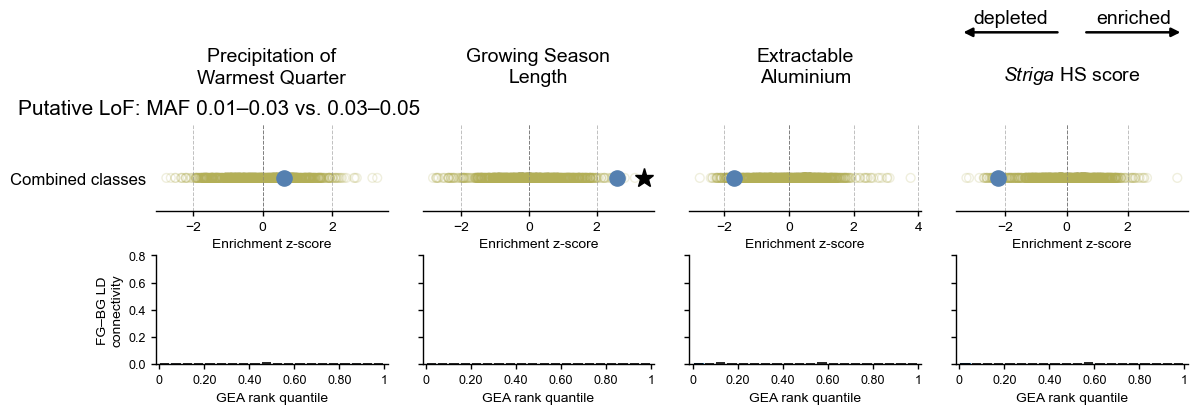

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap.ld_overlap.csv.gz'}


In [67]:
lof_frequency_plot = plot_enrichment_section(
    coding_result_files, lof_contrast_labels, env_id_list,
    env_metadata_df, [['all', 'Combined classes']],
    f'{coding_figure_prefix}.lof_frequency.enrichment_and_overlap',
    figsize=(12, 4.0), section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.45, height_ratios=(0.8, 1)),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(lof_frequency_plot['files'])


### 1.4 Epigenomic features

Compare GEA signals within accessible chromatin regions (ACRs) and unmethylated regions (UMRs), using their annotated boundaries without additional flanks. Analyze each annotation against the Genome background and within Proximal and Distal regions. Proximal comprises gene bodies and 5 kb flanks on each side; Distal lies outside this range. Each foreground is compared with the remaining sites in its background.

All six comparisons use genome-wide QC variants with MAF ≥0.05. ACR and UMR membership can overlap other annotations; enrichment describes association patterns rather than demonstrating a regulatory mechanism.


### 1.4 表观基因组特征

比较开放染色质区域（ACRs）和未甲基化区域（UMRs）中的GEA信号，使用注释边界，不额外增加侧翼范围。每类注释分别在Genome背景，以及Proximal和Distal区域内分析。Proximal包括基因本体及两侧各5 kb，Distal为该范围之外的区域。各前景集合与相应背景中的其余位点比较。

六组对比均使用MAF ≥0.05的全基因组质控变异。ACR和UMR可以与其他注释重叠；富集描述关联模式，不能直接证明调控机制。


In [68]:
epigenomic_contrast_labels = {
    'ACRs': [
        ('ACR_vs_genome', 'ACRs vs. Genome'),
        ('proximal_ACR_vs_proximal', 'Proximal ACRs vs. Proximal'),
        ('distal_ACR_vs_distal', 'Distal ACRs vs. Distal'),
    ],
    'UMRs': [
        ('UMR_vs_genome', 'UMRs vs. Genome'),
        ('proximal_UMR_vs_proximal', 'Proximal UMRs vs. Proximal'),
        ('distal_UMR_vs_distal', 'Distal UMRs vs. Distal'),
    ],
}
epigenomic_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for labels in epigenomic_contrast_labels.values()
    for contrast_id, _ in labels
}
epigenomic_figure_prefix = f'{la_enrich_dir}/epigenomic_features'
plot_params = dict(
    figsize=(12, 11.4), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)


#### 1.4.1 Accessible chromatin regions (ACRs)

Compare ACR-associated variants with the remaining Genome sites, then compare Proximal and Distal ACRs within their corresponding backgrounds. These three contrasts assess association enrichment across different genomic neighborhoods.


#### 1.4.1 开放染色质区域（ACRs）

先将ACR内的变异与其余Genome位点比较，再将Proximal和Distal ACRs分别与相应背景中的其余位点比较，考察不同基因组邻域中的关联富集。


In [69]:
stage_start = perf_counter()
for contrast_id, label in tqdm(epigenomic_contrast_labels['ACRs'], desc='ACRs enrichment'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] ACRs comparisons ready ({perf_counter() - stage_start:.1f}s)')


ACRs enrichment: 100%|██████████| 3/3 [00:00<00:00, 86.16it/s]

Enrichment results already exist for contrast ACR_vs_genome, skipping.
LD overlap results already exist for contrast ACR_vs_genome. Skipping calculation.
Enrichment results already exist for contrast proximal_ACR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_ACR_vs_proximal. Skipping calculation.
Enrichment results already exist for contrast distal_ACR_vs_distal, skipping.
LD overlap results already exist for contrast distal_ACR_vs_distal. Skipping calculation.
[01:01:37] ACRs comparisons ready (0.0s)


##### Display ACRs enrichment

Three lettered blocks display the Genome, Proximal and Distal comparisons, with four environmental column titles shared at the top. Upper panels show observed and permutation enrichment Z scores for all variants and five MAF classes; stars mark two-sided P <0.05. Lower panels show cross-group LD linkage across GEA-rank bins and its shuffled-score reference.


##### 展示ACRs富集

三组字母编号面板分别展示Genome、Proximal和Distal对比，共用整图顶部的四个环境变量列标题。上半部分展示全部变异及五个MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间的跨组LD联系及打乱分数后的参照。


2026-10-13 01:01:37 Plotting 3 enrichment contrasts


Enrichment panels: 100%|██████████| 3/3 [00:00<00:00,  3.02it/s]


2026-10-13 01:01:46 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap


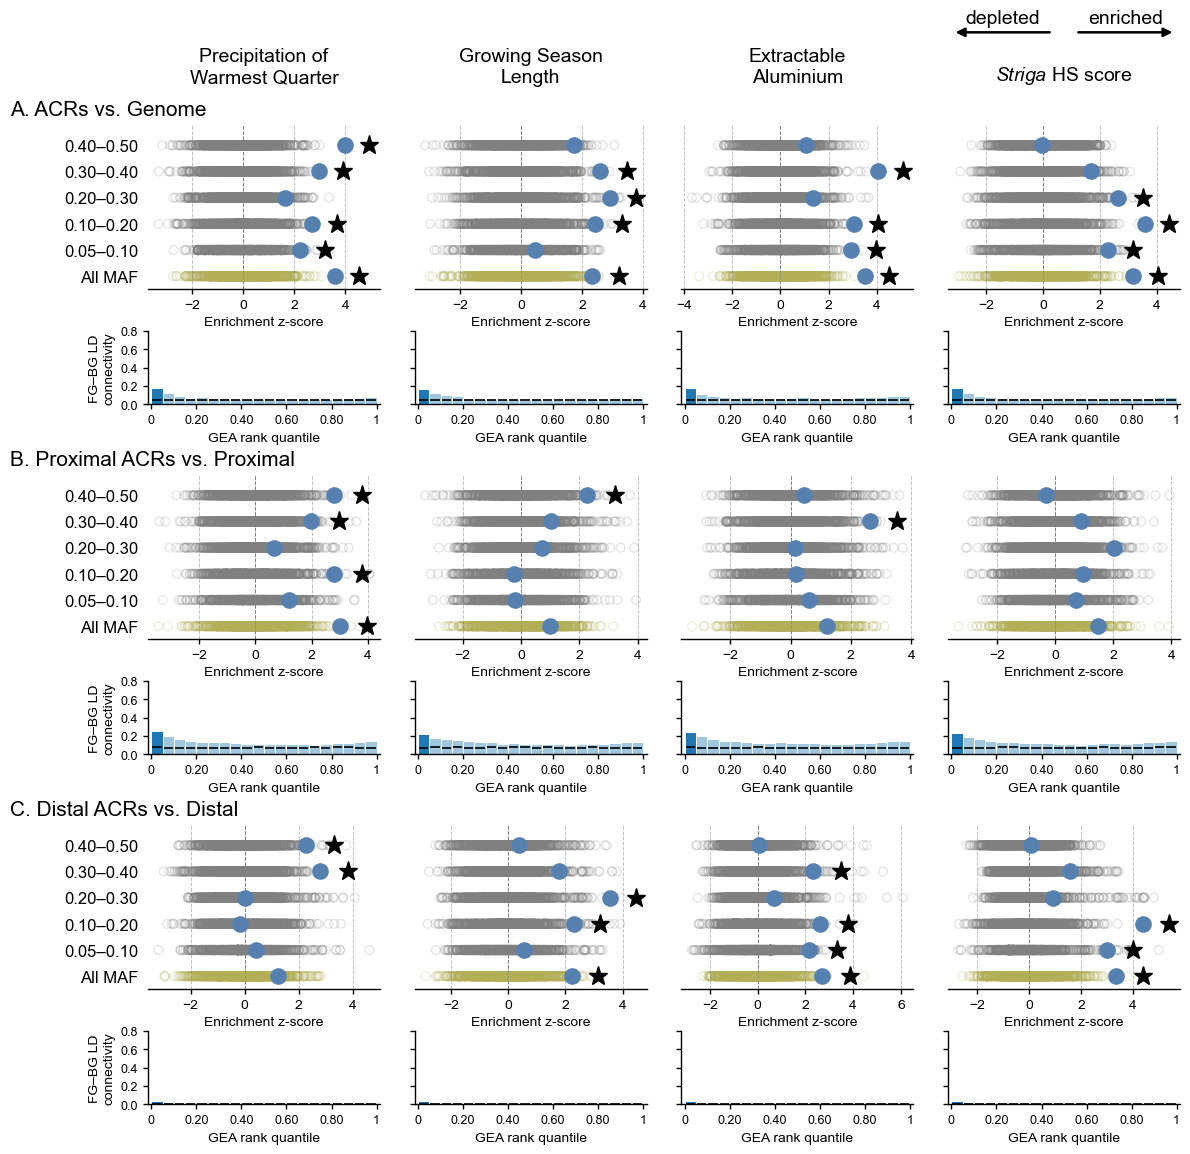

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap.ld_overlap.csv.gz'}


In [70]:
acrs_plot = plot_enrichment_section(
    epigenomic_result_files, epigenomic_contrast_labels['ACRs'], env_id_list,
    env_metadata_df, stratify_label_map,
    f'{epigenomic_figure_prefix}.acrs.enrichment_and_overlap', **plot_params,
)
plt.show()
print(acrs_plot['files'])


#### 1.4.2 Unmethylated regions (UMRs)

Apply the same three backgrounds to UMR-associated variants. Compare genome-wide enrichment with the Proximal and Distal contrasts to describe how UMR association signals vary across genomic neighborhoods.


#### 1.4.2 未甲基化区域（UMRs）

对UMR内的变异采用相同的三种背景。结合全基因组、Proximal和Distal对比，描述UMR关联信号在不同基因组邻域中的分布。


In [71]:
stage_start = perf_counter()
for contrast_id, label in tqdm(epigenomic_contrast_labels['UMRs'], desc='UMRs enrichment'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] UMRs comparisons ready ({perf_counter() - stage_start:.1f}s)')


UMRs enrichment:   0%|          | 0/3 [00:00<?, ?it/s]

UMRs enrichment: 100%|██████████| 3/3 [00:00<00:00, 84.73it/s]

Enrichment results already exist for contrast UMR_vs_genome, skipping.
LD overlap results already exist for contrast UMR_vs_genome. Skipping calculation.
Enrichment results already exist for contrast proximal_UMR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_UMR_vs_proximal. Skipping calculation.
Enrichment results already exist for contrast distal_UMR_vs_distal, skipping.
LD overlap results already exist for contrast distal_UMR_vs_distal. Skipping calculation.
[01:01:51] UMRs comparisons ready (0.0s)


##### Display UMRs enrichment

Three lettered blocks display the Genome, Proximal and Distal comparisons, with four environmental column titles shared at the top. Upper panels show observed and permutation enrichment Z scores for all variants and five MAF classes; stars mark two-sided P <0.05. Lower panels show cross-group LD linkage across GEA-rank bins and its shuffled-score reference.


##### 展示UMRs富集

三组字母编号面板分别展示Genome、Proximal和Distal对比，共用整图顶部的四个环境变量列标题。上半部分展示全部变异及五个MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间的跨组LD联系及打乱分数后的参照。


2026-10-13 01:01:51 Plotting 3 enrichment contrasts


Enrichment panels: 100%|██████████| 3/3 [00:00<00:00,  3.66it/s]


2026-10-13 01:01:58 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap


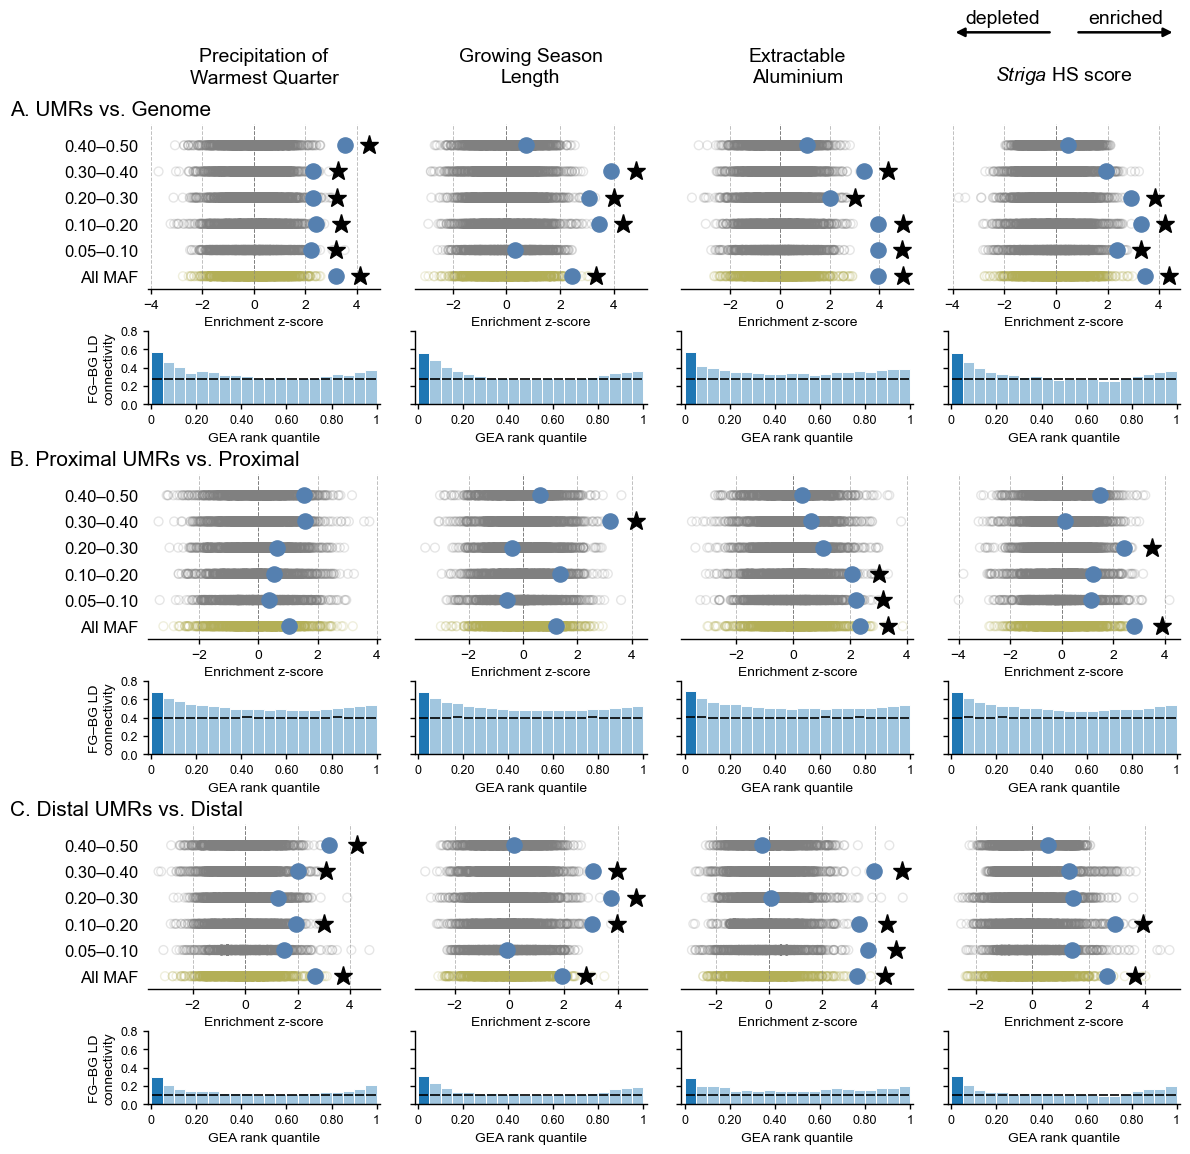

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap.ld_overlap.csv.gz'}


In [72]:
umrs_plot = plot_enrichment_section(
    epigenomic_result_files, epigenomic_contrast_labels['UMRs'], env_id_list,
    env_metadata_df, stratify_label_map,
    f'{epigenomic_figure_prefix}.umrs.enrichment_and_overlap', **plot_params,
)
plt.show()
print(umrs_plot['files'])


### 1.5 riboSNitches

Test whether variants predicted to alter RNA secondary structure have stronger GEA signals than other gene-body variants. riboSNitches are defined by SNPfold CC_BPPROB <0.8; when multiple predictions exist for a variant, the lowest score is used. These predictions describe potential structural changes rather than experimentally established effects.

Use genome-wide QC variants with MAF ≥0.05, restricting both foreground and background to gene bodies without flanks. The foreground contains predicted riboSNitches; the comparison group contains all remaining gene-body variants, including sites without a riboSNitch classification.


### 1.5 riboSNitches

检验预测可能改变RNA二级结构的变异是否具有更强的GEA信号。riboSNitches定义为SNPfold CC_BPPROB <0.8；同一变异有多个预测时，采用最低分值。这些预测描述潜在结构变化，不能等同于经实验确认的效应。

使用MAF ≥0.05的全基因组质控变异，前景和背景均限定于基因本体，不增加侧翼范围。前景为预测的riboSNitches，比较组为其余全部基因本体变异，包括未获得riboSNitch分类的位点。


In [73]:
ribo_contrast_labels = [('riboSNitch_vs_gene_body', 'riboSNitches vs. Gene body')]
ribo_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in ribo_contrast_labels
}
ribo_figure_prefix = f'{la_enrich_dir}/ribosnitches.enrichment_and_overlap'


In [74]:
stage_start = perf_counter()
contrast_id = ribo_contrast_labels[0][0]
contrast = contrasts_settings[contrast_id]
context_df = datasets[contrast['dataset']]
site_contrast_runner(
    contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
    permutations=permutations, top_percent=top_percent, pool_num=pool_num,
    force_recompute=force_recompute,
)
calculate_contrast_ld_overlap(
    contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
    la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
    force_recompute=force_recompute,
)
print(f'[{datetime.now():%H:%M:%S}] riboSNitch comparison ready ({perf_counter() - stage_start:.1f}s)')


Enrichment results already exist for contrast riboSNitch_vs_gene_body, skipping.
LD overlap results already exist for contrast riboSNitch_vs_gene_body. Skipping calculation.
[01:02:03] riboSNitch comparison ready (0.0s)


#### Display riboSNitch enrichment

For each environment, upper panels show observed and permutation enrichment Z scores for all variants and five MAF classes; stars mark two-sided P <0.05. Lower panels show LD linkage between the foreground and remaining gene-body variants by GEA-rank bin, with a shuffled-score reference. Raw association-score ratios are retained in the exported data.


#### 展示riboSNitch富集

对各环境变量，上半部分展示全部变异及五个MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间中，前景与其余基因本体变异之间的LD联系及打乱分数后的参照。原始关联强度比值保留在导出数据中。


2026-10-13 01:02:03 Plotting 1 enrichment contrasts


Enrichment panels: 100%|██████████| 1/1 [00:00<00:00,  3.59it/s]


2026-10-13 01:02:06 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap


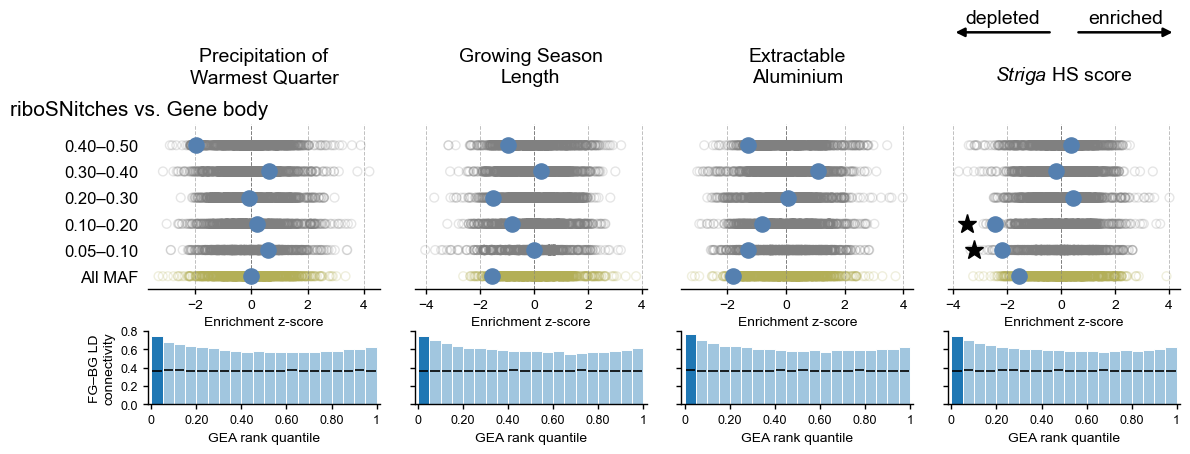

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap.ld_overlap.csv.gz'}


In [75]:
ribo_plot = plot_enrichment_section(
    ribo_result_files, ribo_contrast_labels, env_id_list,
    env_metadata_df, stratify_label_map, ribo_figure_prefix,
    figsize=(12, 4.4), section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=False, env_titles_first_only=True,
)
plt.show()
print(ribo_plot['files'])


### 1.6 Phylogenetic conservation

Compare GEA signals across four phyloP categories within gene bodies and 15 kb flanks on both sides. Conserved sites have phyloP >1, neutral sites have −1 ≤phyloP ≤1, and accelerated sites have phyloP <−1. Sites in the same neighborhoods without an evaluable phyloP score form the Non-evaluable category, which does not establish an absence of conservation.

Use genome-wide QC variants with MAF ≥0.05. Each category is compared with all remaining sites in the gene-neighborhood background, rather than with a single other conservation category.


### 1.6 系统发育保守性

在基因本体及两侧各15 kb范围内，比较四类phyloP位点中的GEA信号。保守位点为phyloP >1，中性位点为−1 ≤phyloP ≤1，加速位点为phyloP <−1。同一基因邻域内缺少可评估phyloP分值的位点归为Non-evaluable，不能据此认定其没有保守性。

使用MAF ≥0.05的全基因组质控变异。各类别分别与基因邻域背景中的其余全部位点比较，而非仅与某一个保守性类别比较。


In [76]:
conservation_contrast_labels = [
    ('non_CEs', 'Non-evaluable vs. Gene ±15 kb'),
    ('accelerated_sites', 'Accelerated vs. Gene ±15 kb'),
    ('neutral_sites', 'Neutral vs. Gene ±15 kb'),
    ('conserved_sites', 'Conserved vs. Gene ±15 kb'),
]
conservation_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in conservation_contrast_labels
}
conservation_figure_prefix = f'{la_enrich_dir}/phylogenetic_conservation.enrichment_and_overlap'


In [77]:
stage_start = perf_counter()
for contrast_id, label in tqdm(conservation_contrast_labels, desc='Phylogenetic conservation'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Conservation comparisons ready ({perf_counter() - stage_start:.1f}s)')


Phylogenetic conservation: 100%|██████████| 4/4 [00:00<00:00, 87.01it/s]

Enrichment results already exist for contrast non_CEs, skipping.
LD overlap results already exist for contrast non_CEs. Skipping calculation.
Enrichment results already exist for contrast accelerated_sites, skipping.
LD overlap results already exist for contrast accelerated_sites. Skipping calculation.
Enrichment results already exist for contrast neutral_sites, skipping.
LD overlap results already exist for contrast neutral_sites. Skipping calculation.
Enrichment results already exist for contrast conserved_sites, skipping.
LD overlap results already exist for contrast conserved_sites. Skipping calculation.
[01:02:08] Conservation comparisons ready (0.0s)


#### Display conservation-associated enrichment

Four lettered blocks display Non-evaluable, Accelerated, Neutral and Conserved sites, sharing environmental column titles at the top. Upper panels show observed and permutation enrichment Z scores for all variants and five MAF classes; stars mark two-sided P <0.05. Lower panels show cross-group LD linkage by GEA-rank bin and its shuffled-score reference. Interpret enrichment direction relative to the permutation distribution, with raw association-score ratios retained in the exported data.


#### 展示保守性相关富集

四组字母编号面板依次展示Non-evaluable、Accelerated、Neutral和Conserved位点，共用整图顶部的环境变量列标题。上半部分展示全部变异及五个MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间的跨组LD联系及打乱分数后的参照。结合置换分布判断富集方向，原始关联强度比值保留在导出数据中。


2026-10-13 01:02:08 Plotting 4 enrichment contrasts


Enrichment panels: 100%|██████████| 4/4 [00:02<00:00,  1.99it/s]


2026-10-13 01:02:19 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap


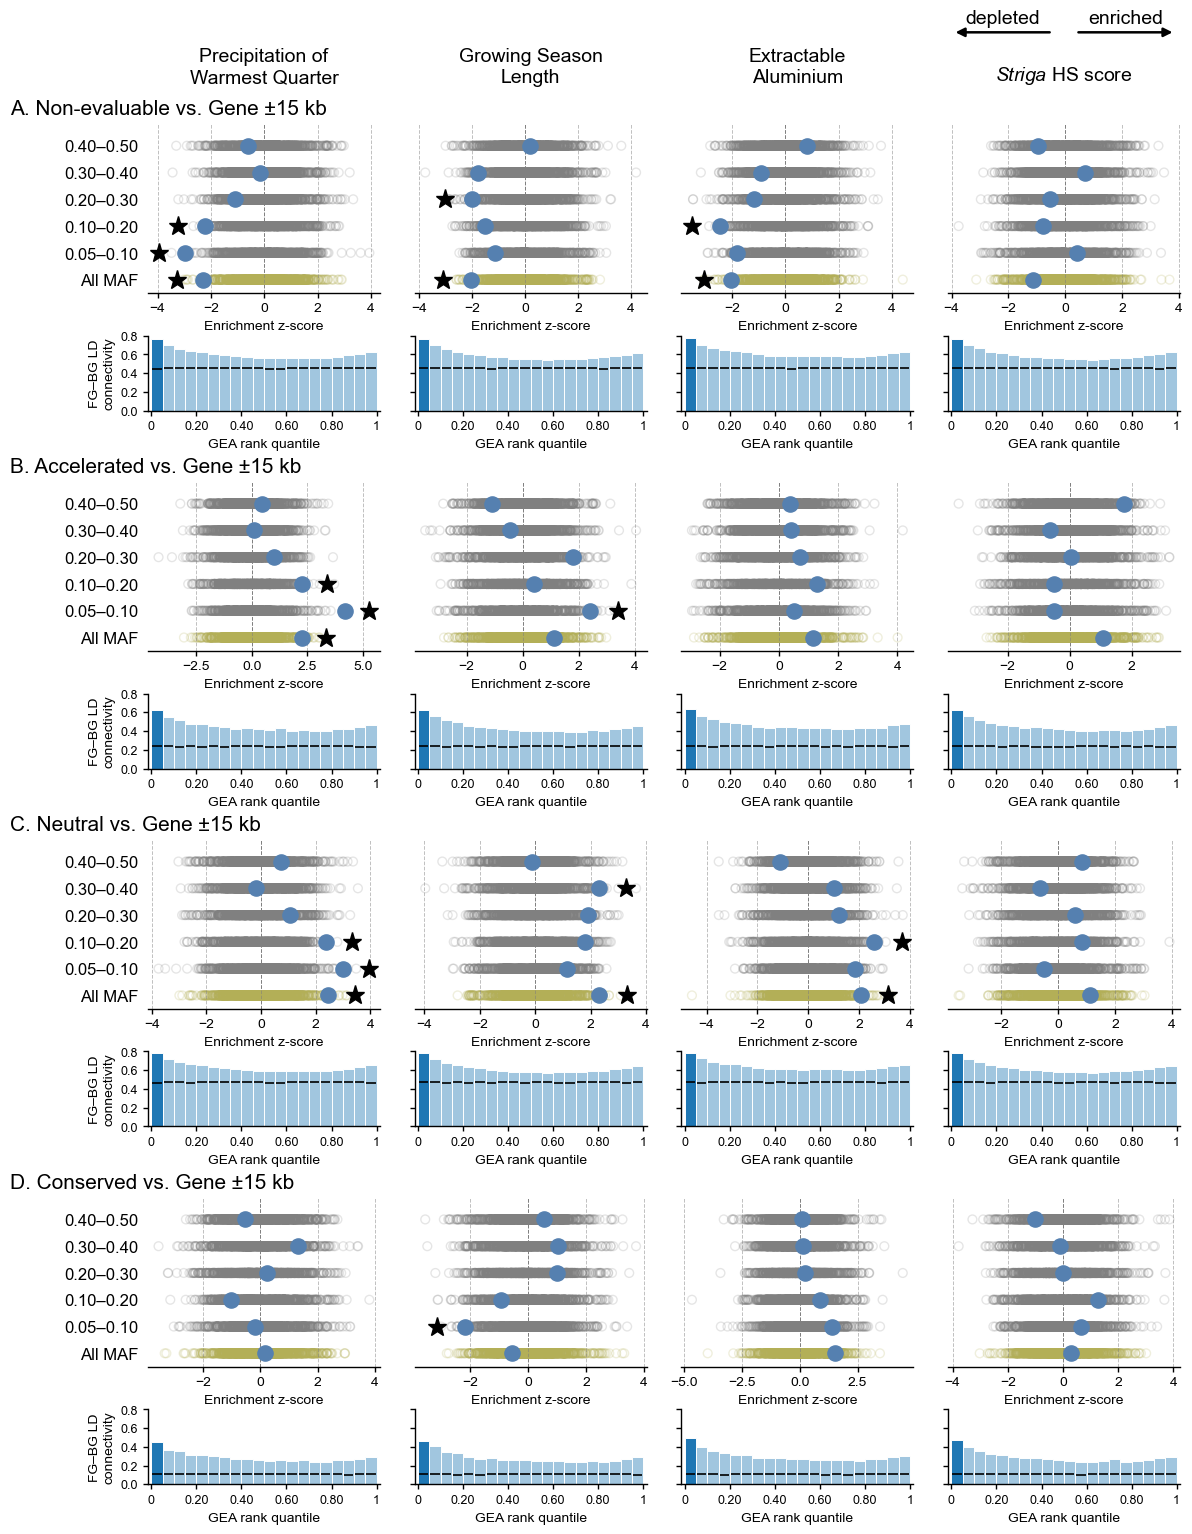

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap.ld_overlap.csv.gz'}


In [78]:
conservation_plot = plot_enrichment_section(
    conservation_result_files, conservation_contrast_labels, env_id_list,
    env_metadata_df, stratify_label_map, conservation_figure_prefix,
    figsize=(12, 15.2), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(conservation_plot['files'])


### 1.7 Minor allele frequency

Compare GEA strength across five MAF classes within gene bodies and 15 kb flanks on each side. Each class is compared with all remaining variants in that neighborhood background. Use genome-wide QC variants with MAF ≥0.05. Intervals include their lower boundary and exclude their upper boundary, except that the final class includes MAF =0.5.

MAF defines the foreground classes, so no additional MAF stratification is applied. This analysis compares association-strength distributions across frequency classes.


### 1.7 次要等位基因频率

在基因本体及两侧各15 kb范围内，比较五个MAF类别中的GEA强度。各类别分别与该邻域背景中的其余全部变异比较，使用MAF ≥0.05的全基因组质控变异。各区间包含下界、不包含上界，最后一个类别例外，包含MAF =0.5。

MAF已用于定义前景类别，不再额外进行MAF分层。本分析比较不同频率类别的关联强度分布。


In [79]:
from src.enrich import plot_set_enrichment

maf_contrast_labels = [
    ('maf_0.05_0.1', '0.05–0.10'),
    ('maf_0.1_0.2', '0.10–0.20'),
    ('maf_0.2_0.3', '0.20–0.30'),
    ('maf_0.3_0.4', '0.30–0.40'),
    ('maf_0.4_0.5', '0.40–0.50'),
]
maf_result_files = {
    contrast_id: f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz'
    for contrast_id, _ in maf_contrast_labels
}
maf_figure_prefix = f'{la_enrich_dir}/minor_allele_frequency.enrichment'


In [80]:
stage_start = perf_counter()
for contrast_id, label in tqdm(maf_contrast_labels, desc='MAF enrichment'):
    contrast = dict(contrasts_settings[contrast_id])
    contrast['maf_stratify'] = ['all']
    site_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] MAF comparisons ready ({perf_counter() - stage_start:.1f}s)')


MAF enrichment: 100%|██████████| 5/5 [00:00<00:00, 337.05it/s]

Enrichment results already exist for contrast maf_0.05_0.1, skipping.
Enrichment results already exist for contrast maf_0.1_0.2, skipping.
Enrichment results already exist for contrast maf_0.2_0.3, skipping.
Enrichment results already exist for contrast maf_0.3_0.4, skipping.
Enrichment results already exist for contrast maf_0.4_0.5, skipping.
[01:02:25] MAF comparisons ready (0.0s)


#### Display MAF-associated enrichment

Rows show MAF classes from 0.05–0.10 at the bottom to 0.40–0.50 at the top; columns show the four environmental variables. Gray hollow points show permutation Z scores, blue points show observations, and stars mark two-sided P <0.05. Interpret direction relative to the permutation distribution; raw association-score ratios are retained in the exported data.


#### 展示MAF相关富集

各行从下至上依次为0.05–0.10至0.40–0.50，四列对应四个环境变量。灰色空心点表示置换Z-score，蓝色点表示观测值，星号表示双侧P <0.05。结合置换分布判断方向，原始关联强度比值保留在导出数据中。


Figure and plot data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/minor_allele_frequency.enrichment.{pdf,png,csv.gz}


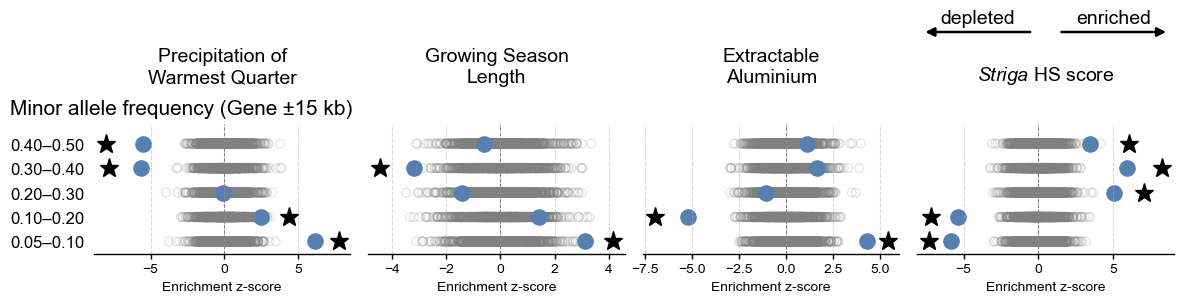

In [81]:
maf_results = {}
for contrast_id, _ in maf_contrast_labels:
    with gzip.open(maf_result_files[contrast_id], 'rt') as handle:
        maf_results[contrast_id] = json.load(handle)

maf_fig, maf_axes = plot_set_enrichment(
    maf_results, env_id_list, env_metadata_df, maf_contrast_labels,
    figsize=(12, 3.2), figure_title='Minor allele frequency (Gene ±15 kb)', figure_title_fontsize=15,
    figure_title_position='below_environments', enrichment_direction=True,
    xlabel='Enrichment z-score', xlabel_fontsize=10, tick_fontsize=10,
    set_tick_fontsize=12, title_fontsize=14,
    output_prefix=maf_figure_prefix, apply_style=False, show=False,
)
plt.show()


### 1.8 Nucleotide diversity

Compare GEA signals across low, intermediate and high nucleotide diversity (π) within gene bodies and 15 kb flanks on each side. π is calculated in 500 bp windows of merged gene neighborhoods using the landrace variants without additional MAF filtering; windows require at least three variant records. Classify retained windows using their π quartiles: low <Q25, intermediate Q25 to below Q75, and high ≥Q75.

GEA comparisons use genome-wide QC variants with MAF ≥0.05. Each π category is compared with the remaining sites in the same gene-neighborhood background. Sites without a valid window π remain in the background but are not assigned to a π category.


### 1.8 核苷酸多样性

在基因本体及两侧各15 kb范围内，比较低、中、高核苷酸多样性（π）区域中的GEA信号。π使用未额外进行MAF过滤的地方品种变异，在合并后的基因邻域内按500 bp窗口计算，窗口至少需含三条变异记录。依据保留窗口的π四分位数分类：低值为<Q25，中值为Q25至Q75以下，高值为≥Q75。

GEA对比使用MAF ≥0.05的全基因组质控变异。各π类别分别与同一基因邻域背景中的其余位点比较。缺少有效窗口π的位点仍保留在背景中，但不归入任何π类别。


In [82]:
diversity_contrast_labels = [
    ('low_pi', 'Low π vs. Gene ±15 kb'),
    ('med_pi', 'Intermediate π vs. Gene ±15 kb'),
    ('high_pi', 'High π vs. Gene ±15 kb'),
]
diversity_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in diversity_contrast_labels
}
diversity_figure_prefix = f'{la_enrich_dir}/nucleotide_diversity.enrichment_and_overlap'


In [83]:
stage_start = perf_counter()
for contrast_id, label in tqdm(diversity_contrast_labels, desc='Nucleotide diversity'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Diversity comparisons ready ({perf_counter() - stage_start:.1f}s)')


Nucleotide diversity: 100%|██████████| 3/3 [00:00<00:00, 86.70it/s]

Enrichment results already exist for contrast low_pi, skipping.
LD overlap results already exist for contrast low_pi. Skipping calculation.
Enrichment results already exist for contrast med_pi, skipping.
LD overlap results already exist for contrast med_pi. Skipping calculation.
Enrichment results already exist for contrast high_pi, skipping.
LD overlap results already exist for contrast high_pi. Skipping calculation.
[01:02:29] Diversity comparisons ready (0.0s)


#### Display diversity-associated enrichment

Three lettered blocks display Low, Intermediate and High π categories, sharing environmental column titles at the top. Upper panels show observed and permutation enrichment Z scores for all variants and five MAF classes; stars mark two-sided P <0.05. Lower panels show cross-group LD linkage by GEA-rank bin and its shuffled-score reference. Interpret enrichment direction relative to the permutation distribution; raw association-score ratios are retained in the exported data.


#### 展示多样性相关富集

三组字母编号面板依次展示Low、Intermediate和High π类别，共用整图顶部的环境变量列标题。上半部分展示全部变异及五个MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间的跨组LD联系及打乱分数后的参照。结合置换分布判断富集方向，原始关联强度比值保留在导出数据中。


2026-10-13 01:02:29 Plotting 3 enrichment contrasts


Enrichment panels: 100%|██████████| 3/3 [00:00<00:00,  3.66it/s]


2026-10-13 01:02:37 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap


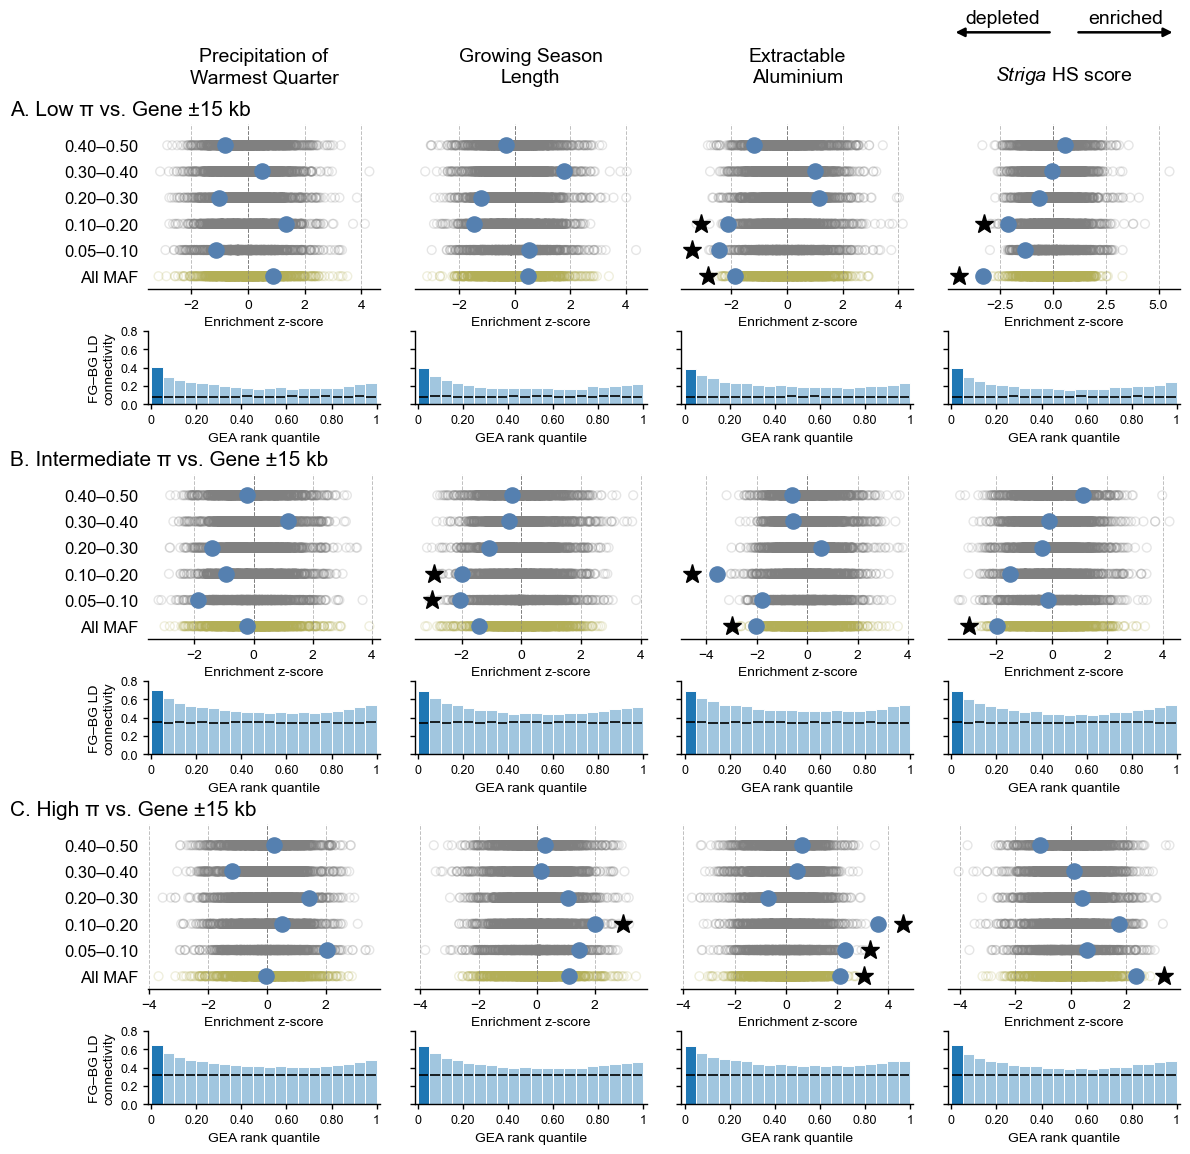

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap.ld_overlap.csv.gz'}


In [84]:
diversity_plot = plot_enrichment_section(
    diversity_result_files, diversity_contrast_labels, env_id_list,
    env_metadata_df, stratify_label_map, diversity_figure_prefix,
    figsize=(12, 11.4), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(diversity_plot['files'])


### 1.9 Components of proximal regions

Compare GEA strength among ACR, UMR and TE components within gene bodies and 5 kb flanks on each side (Proximal). For each pair, compare sites belonging to one annotation but not the other: ACR − TE versus TE − ACR, ACR − UMR versus UMR − ACR, and UMR − TE versus TE − UMR. Exclude shared sites for the two annotations being compared; membership in the third annotation is retained.

Finally compare the ACR ∪ UMR ∪ TE union with Proximal sites outside all three annotations. This tests the association strength of their combined coverage, not their intersection or an interaction effect. Stronger GEA signals describe association evidence rather than establishing greater causal or functional importance.


### 1.9 Proximal区域的组成成分

在基因本体及两侧各5 kb范围（Proximal）内，比较ACR、UMR和TE成分的GEA强度。各两两对比分别比较仅属于其中一类的位点：ACR − TE与TE − ACR、ACR − UMR与UMR − ACR，以及UMR − TE与TE − UMR。排除当前两类共有的位点，但保留可能属于第三类注释的位点。

最后将ACR ∪ UMR ∪ TE并集与三类注释均不属于的Proximal位点比较，检验合并覆盖区域的关联强度，而非三者交集或交互作用。更强的GEA信号描述关联证据，不能据此确定更大的因果或功能贡献。


In [85]:
from src.enrich import summarize_site_contrasts

proximal_contrast_labels = [
    ('proximal_ACR_not_TE_vs_proximal_TE_not_ACR', 'ACR − TE vs. TE − ACR (Proximal)'),
    ('proximal_ACR_not_UMR_vs_proximal_UMR_not_ACR', 'ACR − UMR vs. UMR − ACR (Proximal)'),
    ('proximal_UMR_not_TE_vs_proximal_TE_not_UMR', 'UMR − TE vs. TE − UMR (Proximal)'),
    ('proximal_ACR_TE_UMR_vs_proximal', r'ACR $\cup$ UMR $\cup$ TE vs. Remaining Proximal'),
]
with open(f'{project_dir}/config/contrasts_settings.json') as handle:
    contrasts_settings = json.load(handle)
proximal_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in proximal_contrast_labels
}
proximal_figure_prefix = f'{la_enrich_dir}/proximal_components.enrichment_and_overlap'
site_counts_csv = f'{la_enrich_dir}/proximal_components.site_counts.csv.gz'


In [86]:
site_counts = summarize_site_contrasts(
    datasets['genome'], contrasts_settings,
    [contrast_id for contrast_id, _ in proximal_contrast_labels], site_counts_csv,
)
site_counts.loc[site_counts['STRATUM'] == 'all',
                ['CONTRAST', 'N_FOREGROUND', 'N_BACKGROUND', 'N_TESTED']]


[01:02:43] Summarizing contrast site counts


Contrast site counts: 100%|██████████| 4/4 [00:01<00:00,  3.22it/s]


,CONTRAST,N_FOREGROUND,N_BACKGROUND,N_TESTED
0,proximal_ACR_not_TE_vs_proximal_TE_not_ACR,87332,1011487,1098819
6,proximal_ACR_not_UMR_vs_proximal_UMR_not_ACR,22522,1069151,1091673
12,proximal_UMR_not_TE_vs_proximal_TE_not_UMR,1074070,951596,2025666
18,proximal_ACR_TE_UMR_vs_proximal,2109139,968031,3077170


In [87]:
if (site_counts[['N_FOREGROUND', 'N_BACKGROUND']] == 0).any().any():
    raise ValueError('A comparison or MAF stratum has an empty group; inspect site_counts before computing enrichment.')

stage_start = perf_counter()
for contrast_id, label in tqdm(proximal_contrast_labels, desc='Proximal components'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Proximal comparisons ready ({perf_counter() - stage_start:.1f}s)')


Proximal components: 100%|██████████| 4/4 [00:00<00:00, 71.60it/s]

Enrichment results already exist for contrast proximal_ACR_not_TE_vs_proximal_TE_not_ACR, skipping.
LD overlap results already exist for contrast proximal_ACR_not_TE_vs_proximal_TE_not_ACR. Skipping calculation.
Enrichment results already exist for contrast proximal_ACR_not_UMR_vs_proximal_UMR_not_ACR, skipping.
LD overlap results already exist for contrast proximal_ACR_not_UMR_vs_proximal_UMR_not_ACR. Skipping calculation.
Enrichment results already exist for contrast proximal_UMR_not_TE_vs_proximal_TE_not_UMR, skipping.
LD overlap results already exist for contrast proximal_UMR_not_TE_vs_proximal_TE_not_UMR. Skipping calculation.
Enrichment results already exist for contrast proximal_ACR_TE_UMR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_ACR_TE_UMR_vs_proximal. Skipping calculation.
[01:02:45] Proximal comparisons ready (0.1s)


#### Display Proximal component comparisons

Four lettered blocks share environmental column titles at the top. Upper panels show observed and permutation enrichment Z scores for all sites and five MAF classes; stars mark two-sided P <0.05. Lower panels show cross-group LD linkage by GEA-rank bin and its shuffled-score reference. Interpret each direct comparison using its raw score ratio and permutation P value, rather than ranking components by Z scores from different comparisons alone.


#### 展示Proximal成分对比

四组字母编号面板共用整图顶部的环境变量列标题。上半部分展示全部位点及五个MAF类别的观测与置换富集Z-score，星号表示双侧P <0.05；下半部分展示各GEA排名区间的跨组LD联系及打乱分数后的参照。结合各直接对比的原始关联强度比值及置换P值解释结果，不仅依据不同对比的Z-score大小给成分排序。


2026-10-13 01:02:45 Plotting 4 enrichment contrasts


Enrichment panels: 100%|██████████| 4/4 [00:01<00:00,  3.02it/s]
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


2026-10-13 01:02:56 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap


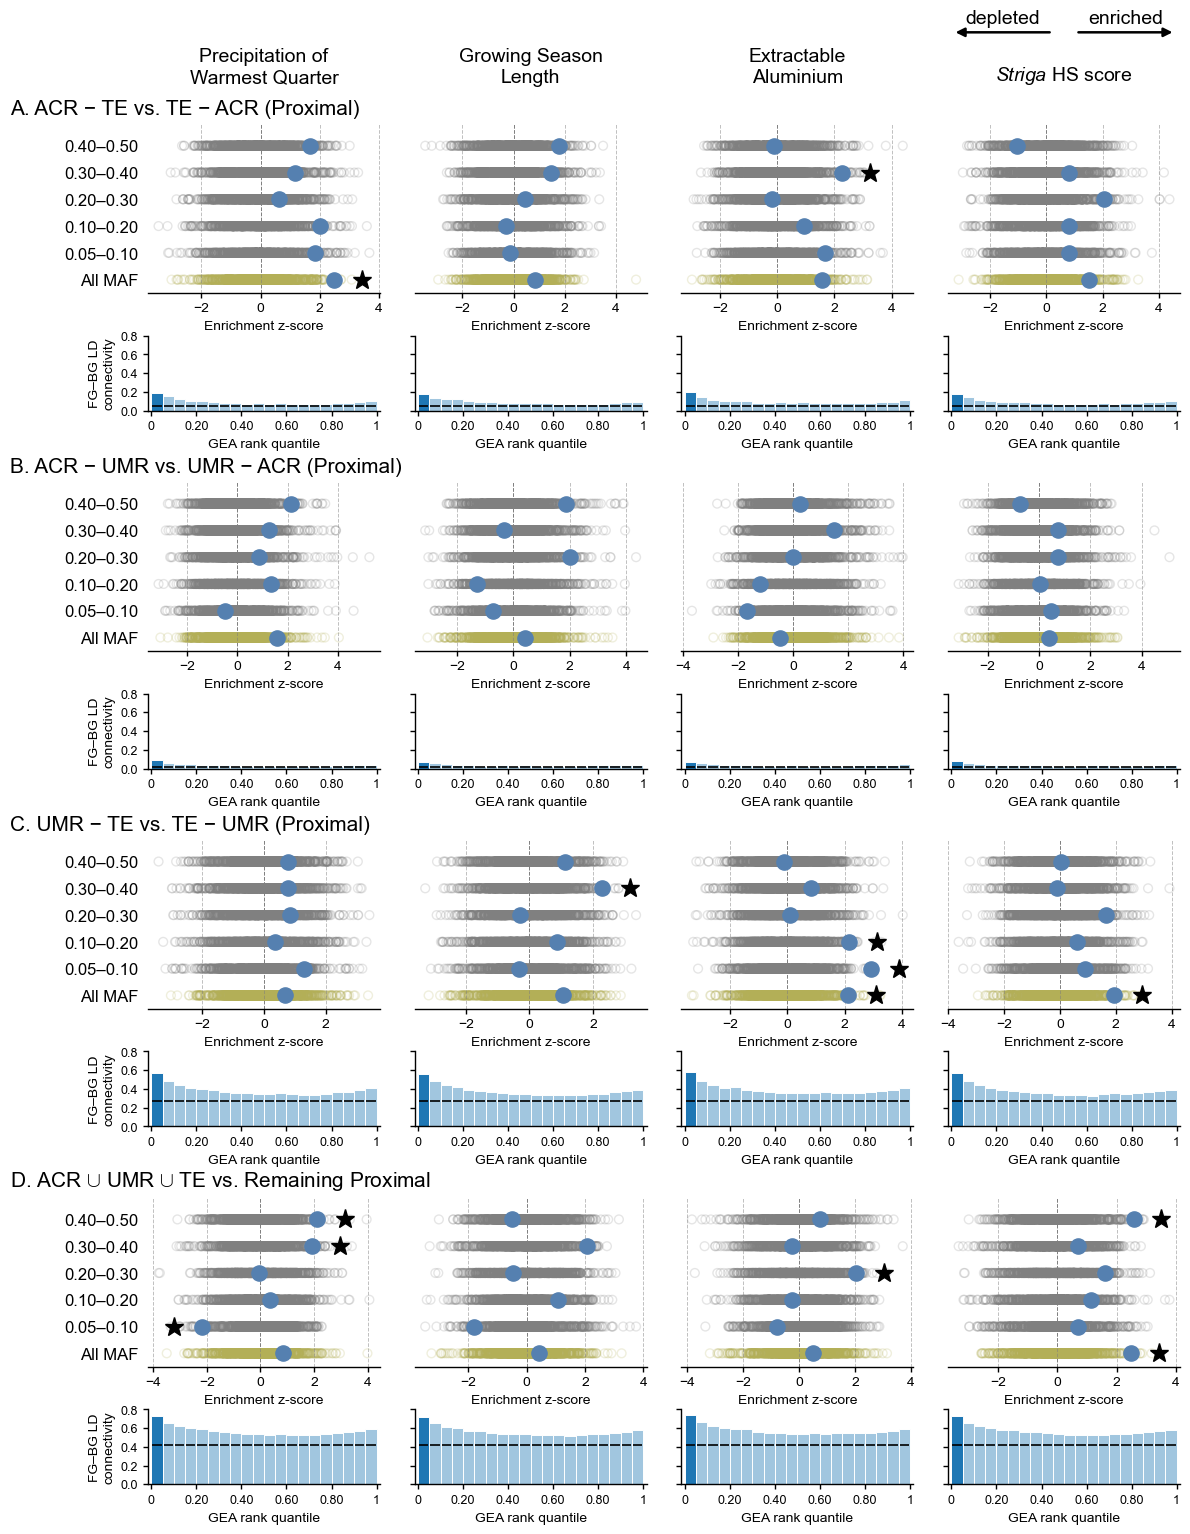

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap.ld_overlap.csv.gz'}


In [88]:
proximal_plot = plot_enrichment_section(
    proximal_result_files, proximal_contrast_labels, env_id_list,
    env_metadata_df, stratify_label_map, proximal_figure_prefix,
    figsize=(12, 15.2), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(proximal_plot['files'])


### 1.10 Gene-level GEA enrichment

Compare environmental associations across gene expression, co-expression network, copy redundancy and recombination categories. For each environment and target category, retain genes with complete association scores, target labels and genomic coordinates. Select the strongest 5% of MAGMA gene associations, including threshold ties, and measure Jaccard overlap with the target set.

Use 1,000 chromosome-wise circular shifts of target labels to obtain a two-sided empirical P value. These are gene-level comparisons; no MAF stratification or site-level LD analysis is applied.


### 1.10 基因级GEA富集

比较基因表达、共表达网络、拷贝冗余和重组率类别中的环境关联。对每个环境变量和目标类别，保留关联分数、目标标签及基因组坐标完整的基因。选取MAGMA关联最强的5%基因，包含阈值处并列值，并计算其与目标集合的Jaccard重叠。

通过1,000次染色体内目标标签循环移位计算双侧经验P值。这些对比均为基因级分析，不进行MAF分层或位点级LD分析。


In [89]:
from src.enrich import gene_contrast_runner, plot_set_enrichment_section

gene_group_labels = [
    ('expression', 'Gene expression'),
    ('network', 'Gene co-expression networks'),
    ('copy', 'Gene copy redundancy'),
    ('recombination', 'Recombination rate'),
]
gene_set_labels = {
    'expression': [
        ('no_expression_genes', 'No detected expression'),
        ('high_variance_genes', 'High expression variability'),
        ('stably_expressed_genes', 'Stable expression'),
    ],
    'network': [
        ('non_module_genes', 'Non-module genes'),
        ('module_genes', 'Non-hub module genes'),
        ('module_hub_genes', 'Module hubs'),
    ],
    'copy': [
        ('single_copy_genes', 'Single-copy genes'),
        ('multi_copy_genes', 'Multiple-copy genes'),
        ('orphan_genes', 'Orphan genes'),
    ],
    'recombination': [
        ('low_recombination_genes', 'Low recombination'),
        ('med_recombination_genes', 'Intermediate recombination'),
        ('high_recombination_genes', 'High recombination'),
    ],
}
gene_result_files = {
    contrast_id: f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz'
    for labels in gene_set_labels.values()
    for contrast_id, _ in labels
}
gene_figure_prefix = f'{la_enrich_dir}/gene_level_features.enrichment'


#### 1.10.1 Gene expression

Distinguish genes with no detected expression, high expression variability and stable expression using TPM >2. Genes without retained expression in any sample form the no-expression category. High-variability genes have standardized residuals >1 relative to the LOWESS mean–variance relationship; stable genes have residuals <1 and retained expression in every sample.

These categories do not cover all genes. Genes absent from the expression table are not classified as having no expression; unclassified genes remain in the association background.


#### 1.10.1 基因表达

以TPM >2定义有效表达，区分未检测到表达、表达高变异及稳定表达基因。所有样本均无有效表达的基因归为无表达；相对于LOWESS均值–方差关系，标准化残差 >1的基因归为高变异，残差 <1且所有样本均有有效表达的基因归为稳定表达。

这些类别不覆盖所有基因。表达表未收录的基因不归为无表达，未分类基因仍保留在关联背景中。


In [90]:
stage_start = perf_counter()
for contrast_id, label in tqdm(gene_set_labels['expression'], desc='Gene expression'):
    contrast = contrasts_settings[contrast_id]
    gene_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Gene expression results ready ({perf_counter() - stage_start:.1f}s)')


Gene expression: 100%|██████████| 3/3 [00:00<00:00, 238.86it/s]

Enrichment results already exist for contrast no_expression_genes, skipping.
Enrichment results already exist for contrast high_variance_genes, skipping.
Enrichment results already exist for contrast stably_expressed_genes, skipping.
[01:03:02] Gene expression results ready (0.0s)


#### 1.10.2 Gene co-expression networks

Compare genes outside co-expression modules, non-hub module members and module hubs. These three categories are mutually exclusive; hubs are defined by within-module connectivity and centrality.


#### 1.10.2 基因共表达网络

比较共表达模块外基因、模块中的非枢纽成员和模块枢纽基因。三类互不重叠，枢纽依据模块内连接程度和中心性定义。


In [91]:
stage_start = perf_counter()
for contrast_id, label in tqdm(gene_set_labels['network'], desc='Gene co-expression networks'):
    contrast = contrasts_settings[contrast_id]
    gene_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Gene co-expression networks results ready ({perf_counter() - stage_start:.1f}s)')


Gene co-expression networks: 100%|██████████| 3/3 [00:00<00:00, 405.55it/s]

Enrichment results already exist for contrast non_module_genes, skipping.
Enrichment results already exist for contrast module_genes, skipping.
Enrichment results already exist for contrast module_hub_genes, skipping.
[01:03:02] Gene co-expression networks results ready (0.0s)


#### 1.10.3 Gene copy redundancy

Compare single-copy and multiple-copy genes within Poaceae hierarchical orthogroups. Genes without an orthogroup assignment form the orphan category.


#### 1.10.3 基因拷贝冗余

比较禾本科层级直系同源组中的单拷贝和多拷贝基因。未获得直系同源组分配的基因归为orphan类别。


In [92]:
stage_start = perf_counter()
for contrast_id, label in tqdm(gene_set_labels['copy'], desc='Gene copy redundancy'):
    contrast = contrasts_settings[contrast_id]
    gene_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Gene copy redundancy results ready ({perf_counter() - stage_start:.1f}s)')


Gene copy redundancy: 100%|██████████| 3/3 [00:00<00:00, 252.05it/s]

Enrichment results already exist for contrast single_copy_genes, skipping.
Enrichment results already exist for contrast multi_copy_genes, skipping.
Enrichment results already exist for contrast orphan_genes, skipping.
[01:03:02] Gene copy redundancy results ready (0.0s)


#### 1.10.4 Recombination rate

Compare low, intermediate and high gene recombination rates defined by Q25 and Q75. Gene rates are means of overlapping map intervals without overlap-length weighting. Genes without mapped rates remain in the common association background but are not assigned to a rate category.


#### 1.10.4 重组率

依据Q25和Q75比较低、中、高基因重组率类别。基因重组率为重叠图谱区间的均值，不按重叠长度加权。缺少图谱重组率的基因仍保留在共同关联背景中，但不归入任何重组率类别。


In [93]:
stage_start = perf_counter()
for contrast_id, label in tqdm(gene_set_labels['recombination'], desc='Recombination rate'):
    contrast = contrasts_settings[contrast_id]
    gene_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Recombination rate results ready ({perf_counter() - stage_start:.1f}s)')


Recombination rate: 100%|██████████| 3/3 [00:00<00:00, 239.62it/s]

Enrichment results already exist for contrast low_recombination_genes, skipping.
Enrichment results already exist for contrast med_recombination_genes, skipping.
Enrichment results already exist for contrast high_recombination_genes, skipping.
[01:03:03] Recombination rate results ready (0.0s)


#### Display gene-level enrichment

Four lettered groups share the environmental column titles at the top. Each row represents a gene category. Gray hollow points show permutation Z scores; blue points show observed Jaccard overlaps transformed to the same scale. Stars mark two-sided P <0.05. Raw Jaccard values and per-environment background counts are retained in the exported data.


#### 展示基因级富集

四组字母编号面板共用整图顶部的环境变量列标题，各行表示一个基因类别。灰色空心点展示置换Z-score，蓝色点展示转换至相同尺度的观测Jaccard重叠，星号表示双侧P <0.05。原始Jaccard值及各环境变量的背景数量保留在导出数据中。


[01:03:03] Plotting grouped enrichment sets


Enrichment groups: 100%|██████████| 4/4 [00:00<00:00,  9.23it/s]


[01:03:08] Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_level_features.enrichment


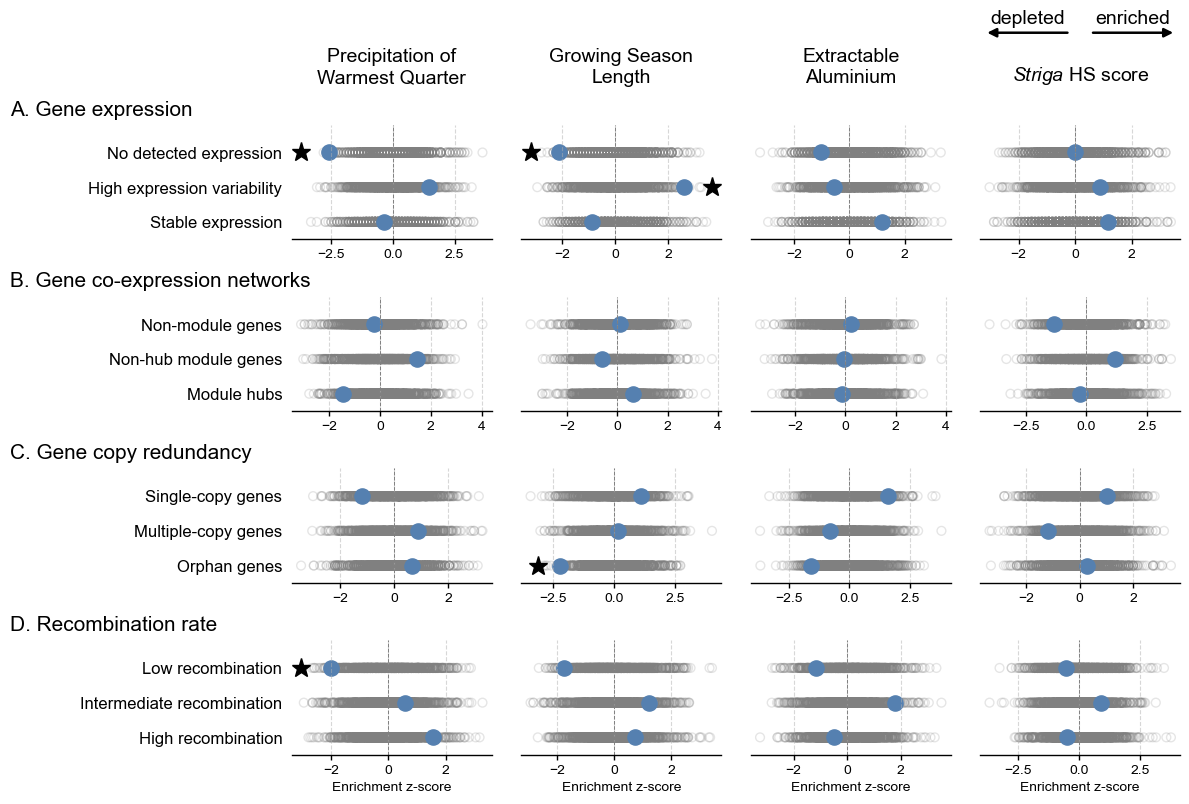

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_level_features.enrichment.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_level_features.enrichment.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_level_features.enrichment.csv.gz'}


In [94]:
gene_plot = plot_set_enrichment_section(
    gene_result_files, gene_group_labels, gene_set_labels,
    env_id_list, env_metadata_df, gene_figure_prefix,
    figsize=(12, 8), block_gap=0.5, section_title_fontsize=15,
    value_column='JACCARD',
    panel_params=dict(tick_fontsize=10, set_tick_fontsize=12, title_fontsize=14),
)
plt.show()
print(gene_plot['files'])


### 1.11 Main figure: genomic and gene features

Summarize nine groups of GEA enrichment comparisons across the four environmental variables. A–D cover classic molecular evolution hypotheses; E–I cover functional genomics hypotheses. Site rows state their comparison background and use the combined `all` result, without MAF stratification or LD panels. Gene-structure rows use the Genic background, comprising gene bodies and 2 kb flanks.

Gray hollow points show permutation Z scores, blue points show observations, and stars mark two-sided P <0.05. Site observations are upper-tail association-score ratios; gene observations are Jaccard overlaps. Z scores describe direction relative to each comparison's permutation distribution, rather than a common effect-size scale across rows.


### 1.11 主图：基因组与基因特征

汇总四个环境变量下九组GEA富集对比。A–D对应经典分子进化假说，E–I对应功能基因组学假说。位点级各行标明对比背景，仅使用合并的`all`结果，不展示MAF分层或LD面板。基因结构采用Genic背景，即基因本体及两侧各2 kb。

灰色空心点表示置换Z-score，蓝色点表示观测值，星号表示双侧P <0.05。位点级观测统计量为上尾关联强度比值，基因级为Jaccard重叠。Z-score描述相对于各自置换分布的方向，不是跨行统一的效应量尺度。


In [99]:
from src.enrich import plot_set_enrichment_section

main_group_labels = [
    ('compartments', 'Genomic compartments'),
    ('expression', 'Gene expression'),
    ('structure', 'Gene Structure'),
    ('coding', 'Coding Mutations'),
    ('ACRs', 'Accessible chromatin regions'),
    ('UMRs', 'Unmethylated regions'),
    ('network', 'Gene regulatory network'),
    ('copy', 'Gene copy redundancy'),
    ('ribo', 'riboSNitches'),
]
# Rows are ordered from top to bottom within each group.
main_set_labels = {
    'compartments': [
        ('TE_vs_genome', 'TE vs. Genome'),
        ('distal_TE_vs_distal', 'Distal TEs vs. Distal'),
        ('other_intergenic_vs_genome', 'Other intergenic vs. Genome'),
        ('proximal_TE_vs_proximal', 'Proximal TEs vs. Proximal'),
        ('genic_2kb_vs_genome', 'Genic vs. Genome'),
    ],
    'expression': [
        ('no_expression_genes', 'Genes with no detected expr.'),
        ('high_variance_genes', 'Genes with high var. expr.'),
        ('stably_expressed_genes', 'Genes with stable expr.'),
    ],
    'structure': [
        ('upstream_2kb_vs_genic', 'Upstream (2 kb) vs. Genic'),
        ('five_prime_UTR_vs_genic', "5′ UTR vs. Genic"),
        ('CDS_vs_genic', 'CDS vs. Genic'),
        ('intron_vs_genic', 'Intron vs. Genic'),
        ('three_prime_UTR_vs_genic', "3′ UTR vs. Genic"),
        ('downstream_2kb_vs_genic', 'Downstream (2 kb) vs. Genic'),
    ],
    'coding': [
        ('synonymous_vs_CDS', 'Synonymous vs. CDS'),
        ('missense_vs_CDS', 'Missense vs. CDS'),
        ('putative_LoF_vs_CDS', 'Putative loss-of-function vs. CDS'),
    ],
    'ACRs': [
        ('ACR_vs_genome', 'ACRs vs. Genome'),
        ('distal_ACR_vs_distal', 'Distal ACRs vs. Distal'),
        ('proximal_ACR_vs_proximal', 'Proximal ACRs vs. Proximal'),
    ],
    'UMRs': [
        ('UMR_vs_genome', 'UMRs vs. Genome'),
        ('distal_UMR_vs_distal', 'Distal UMRs vs. Distal'),
        ('proximal_UMR_vs_proximal', 'Proximal UMRs vs. Proximal'),
    ],
    'network': [
        ('non_module_genes', 'Non-module genes'),
        ('module_genes', 'Module genes'),
        ('module_hub_genes', 'Module hubs'),
    ],
    'copy': [
        ('orphan_genes', 'Orphan genes'),
        ('multi_copy_genes', 'Multi-copy genes'),
        ('single_copy_genes', 'Single-copy genes'),
    ],
    'ribo': [('riboSNitch_vs_gene_body', 'riboSNitches vs. Gene body')],
}
main_result_files = {
    contrast_id: f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz'
    for labels in main_set_labels.values()
    for contrast_id, _ in labels
}
main_statistic_columns = {
    group_id: 'JACCARD' if group_id in ['expression', 'network', 'copy'] else 'SCORE_RATIO'
    for group_id, _ in main_group_labels
}
hypothesis_groups = [
    dict(label='Classic molecular evolution hypotheses', color='#D95F02',
         group_ids=['compartments', 'expression', 'structure', 'coding']),
    dict(label='Functional genomics hypotheses', color='#A32B9A',
         group_ids=['ACRs', 'UMRs', 'network', 'copy', 'ribo']),
]
main_figure_prefix = f'{la_enrich_dir}/genomic_gene_features.main'


[01:39:08] Plotting grouped enrichment sets


Enrichment groups: 100%|██████████| 9/9 [00:02<00:00,  4.33it/s]


[01:39:21] Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_gene_features.main


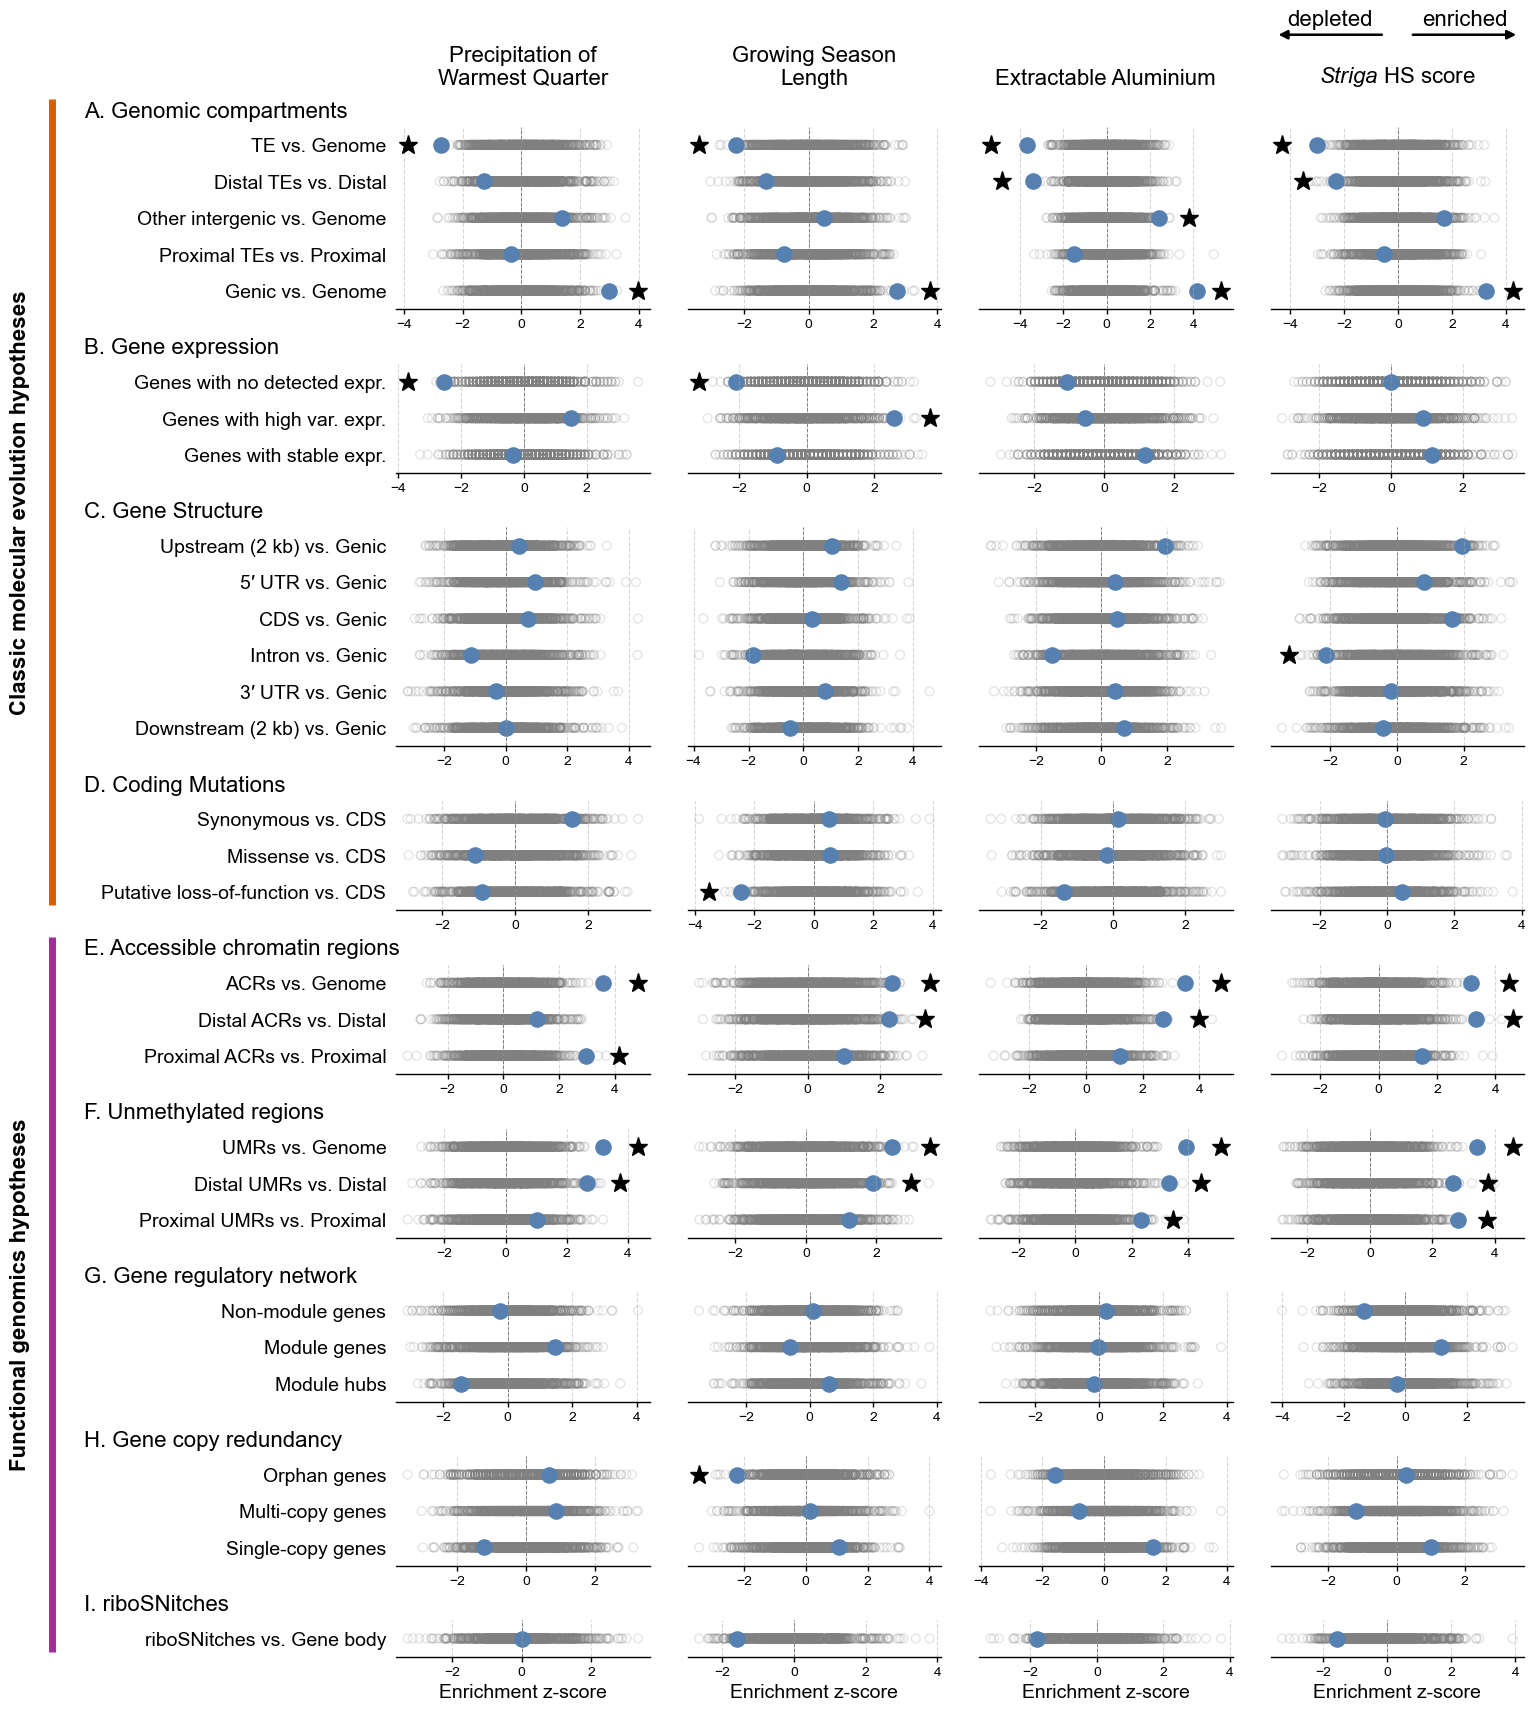

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_gene_features.main.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_gene_features.main.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_gene_features.main.csv.gz'}


In [101]:
main_plot = plot_set_enrichment_section(
    main_result_files, main_group_labels, main_set_labels,
    env_id_list, env_metadata_df, main_figure_prefix,
    figsize=(16, 17), block_gap=0.45, section_title_fontsize=16,
    left=0.285, heading_x=0.09,
    value_column=main_statistic_columns, hypothesis_groups=hypothesis_groups,
    hypothesis_line_x=0.07, hypothesis_label_x=0.05, hypothesis_fontsize=16,
    hypothesis_linewidth=5, hypothesis_bottom_offset=0.05, hypothesis_fontweight='bold',
    header_labels=[
        'Precipitation of\nWarmest Quarter', 'Growing Season\nLength',
        'Extractable Aluminium', 'Striga HS score',
    ],
    panel_params=dict(
        tick_fontsize=10, set_tick_fontsize=14, title_fontsize=16, xlabel_fontsize=14,
        perm_size=40, obs_size=120, star_size=14, wspace=0.15, symmetric_xlim=True,
        ylim_pad=(0.5, 0.5),
    ),
)
plt.show()
print(main_plot['files'])


Figure 3. Enrichments of GEAs across categories of functional variation. Hypotheses for the contexts and characteristics of locally adaptive variants are divided into “Classic molecular evolution hypotheses” (A-D) and “Functional genomics hypotheses” (E-I). Enrichments were tested on the top 5% of GEAs. Observed values (blue) are calculated as a z-score using 1,000 null permutations (gray). Significant enrichments are indicated by stars (two-sided empirical P<0.05). 

## 2. Enrichment Analysis of consistent selection

In [2]:
cs_enrich_dir = os.path.join(enrich_dir, "consistent_selection")
os.makedirs(cs_enrich_dir, exist_ok=True)

Read annotation fractions, π and Tajima’s D from the single 500 bp HDF table produced by notebook 02. Keep its numeric values unchanged in `genome_windows_df`; convert only annotation fractions exceeding 0.75 to foreground membership in a separate analysis copy.


从笔记 02 生成的唯一 500 bp HDF 表读取注释比例、π 和 Tajima’s D。在 `genome_windows_df` 中保留原始数值；仅在独立的分析副本中，将大于 0.75 的注释比例转为前景成员标记。


In [ ]:
genome_windows_contexts_h5 = f'{results_dir}/genome_windows_contexts.b500.h5'
context_threshold = 0.75

genome_windows_df = pd.read_hdf(genome_windows_contexts_h5, key='df')
genome_windows_contexts_df = genome_windows_df.copy()
genome_windows_contexts_df['ID'] = (
    genome_windows_contexts_df['CHROM'] + ':'
    + genome_windows_contexts_df['START'].astype(str) + '-'
    + genome_windows_contexts_df['END'].astype(str)
)
statistics_columns = ['VARIANT_COUNT', 'SNP_COUNT', 'PI', 'TajimaD', 'meanCmPerMb']
context_columns = [
    column for column in genome_windows_contexts_df.columns
    if column not in ['ID', 'CHROM', 'START', 'END'] + statistics_columns
]
for context_id in context_columns:
    genome_windows_contexts_df[context_id] = (
        genome_windows_contexts_df[context_id] > context_threshold
    )
genome_windows_contexts_df = genome_windows_contexts_df[
    ['ID'] + [column for column in genome_windows_contexts_df.columns if column != 'ID']
]
genome_windows_contexts_df['genome'] = True
genome_windows_contexts_df


In [23]:
import os
import json

contrasts_settings_json_file = os.path.join(os.getcwd(), "config", "contrasts_settings.json")
with open(contrasts_settings_json_file, "r") as f:
    contrasts_settings = json.load(f)

In [24]:
trait_id_list = ['TajimaD', 'PI']

In [25]:
contrast_ids = ['genic_2kb_vs_genome',
 'TE_vs_genome',
 'proximal_TE_vs_proximal',
 'distal_TE_vs_distal',
 'other_intergenic_vs_genome',
 'upstream_2kb_vs_genic',
 'five_prime_UTR_vs_genic',
 'CDS_vs_genic',
 'intron_vs_genic',
 'three_prime_UTR_vs_genic',
 'downstream_2kb_vs_genic',
 'upstream_2kb_vs_genome',
 'five_prime_UTR_vs_genome',
 'CDS_vs_genome',
 'intron_vs_genome',
 'three_prime_UTR_vs_genome',
 'downstream_2kb_vs_genome',
 'ACR_vs_genome',
 'proximal_ACR_vs_proximal',
 'distal_ACR_vs_distal',
 'UMR_vs_genome',
 'proximal_UMR_vs_proximal',
 'distal_UMR_vs_distal',
 'proximal_ACR_TE_UMR_vs_proximal',
 'not_proximal_ACR_TE_UMR_vs_proximal',
 'proximal_ACR_not_TE_vs_proximal_TE_not_ACR',
]

In [30]:
from src.enrich import win_contrast_runner, build_enrich_data_df
import numpy as np

results_json_files = {}

for contrast_id in contrast_ids:

    contrast_json = contrasts_settings[contrast_id]
    contrast_json['target'] = 'foreground'
    contrast_json

    contexts_df = build_enrich_data_df(genome_windows_contexts_df, contrast_json, trait_id_list, other_columns=[])
    quant = 0.05
    for trait_id in trait_id_list:
        lower_quantile = np.quantile(contexts_df[trait_id].dropna(), quant)
        nonnan_mask = contexts_df[trait_id].notna()
        contexts_df.loc[nonnan_mask & (contexts_df[trait_id] <= lower_quantile), f'{trait_id}_lower_quantile'] = True
        contexts_df.loc[nonnan_mask & (contexts_df[trait_id] > lower_quantile), f'{trait_id}_lower_quantile'] = False
        contexts_df.drop(columns=[f'{trait_id}'], inplace=True)
        contexts_df.rename(columns={f'{trait_id}_lower_quantile': f'{trait_id}'}, inplace=True)

    output_dir = f'{cs_enrich_dir}/{contrast_id}'
    os.makedirs(output_dir, exist_ok=True)

    results_json_file = win_contrast_runner(contrast_id, contrast_json, contexts_df, trait_id_list, output_dir, permutations=1000)
    results_json_files[contrast_id] = results_json_file

genic_2kb_vs_genome / TajimaD: 1327374/1439822 windows retained; 338719 target, 66369 trait windows
genic_2kb_vs_genome / PI: 1327397/1439822 windows retained; 338729 target, 66371 trait windows
TE_vs_genome / TajimaD: 1327374/1439822 windows retained; 768603 target, 66369 trait windows
TE_vs_genome / PI: 1327397/1439822 windows retained; 768610 target, 66371 trait windows
proximal_TE_vs_proximal / TajimaD: 466934/540138 windows retained; 98771 target, 23347 trait windows
proximal_TE_vs_proximal / PI: 466947/540138 windows retained; 98771 target, 23348 trait windows
distal_TE_vs_distal / TajimaD: 860440/899684 windows retained; 669832 target, 43022 trait windows
distal_TE_vs_distal / PI: 860450/899684 windows retained; 669839 target, 43023 trait windows
other_intergenic_vs_genome / TajimaD: 1327374/1439822 windows retained; 179890 target, 66369 trait windows
other_intergenic_vs_genome / PI: 1327397/1439822 windows retained; 179894 target, 66371 trait windows
upstream_2kb_vs_genic / Taj

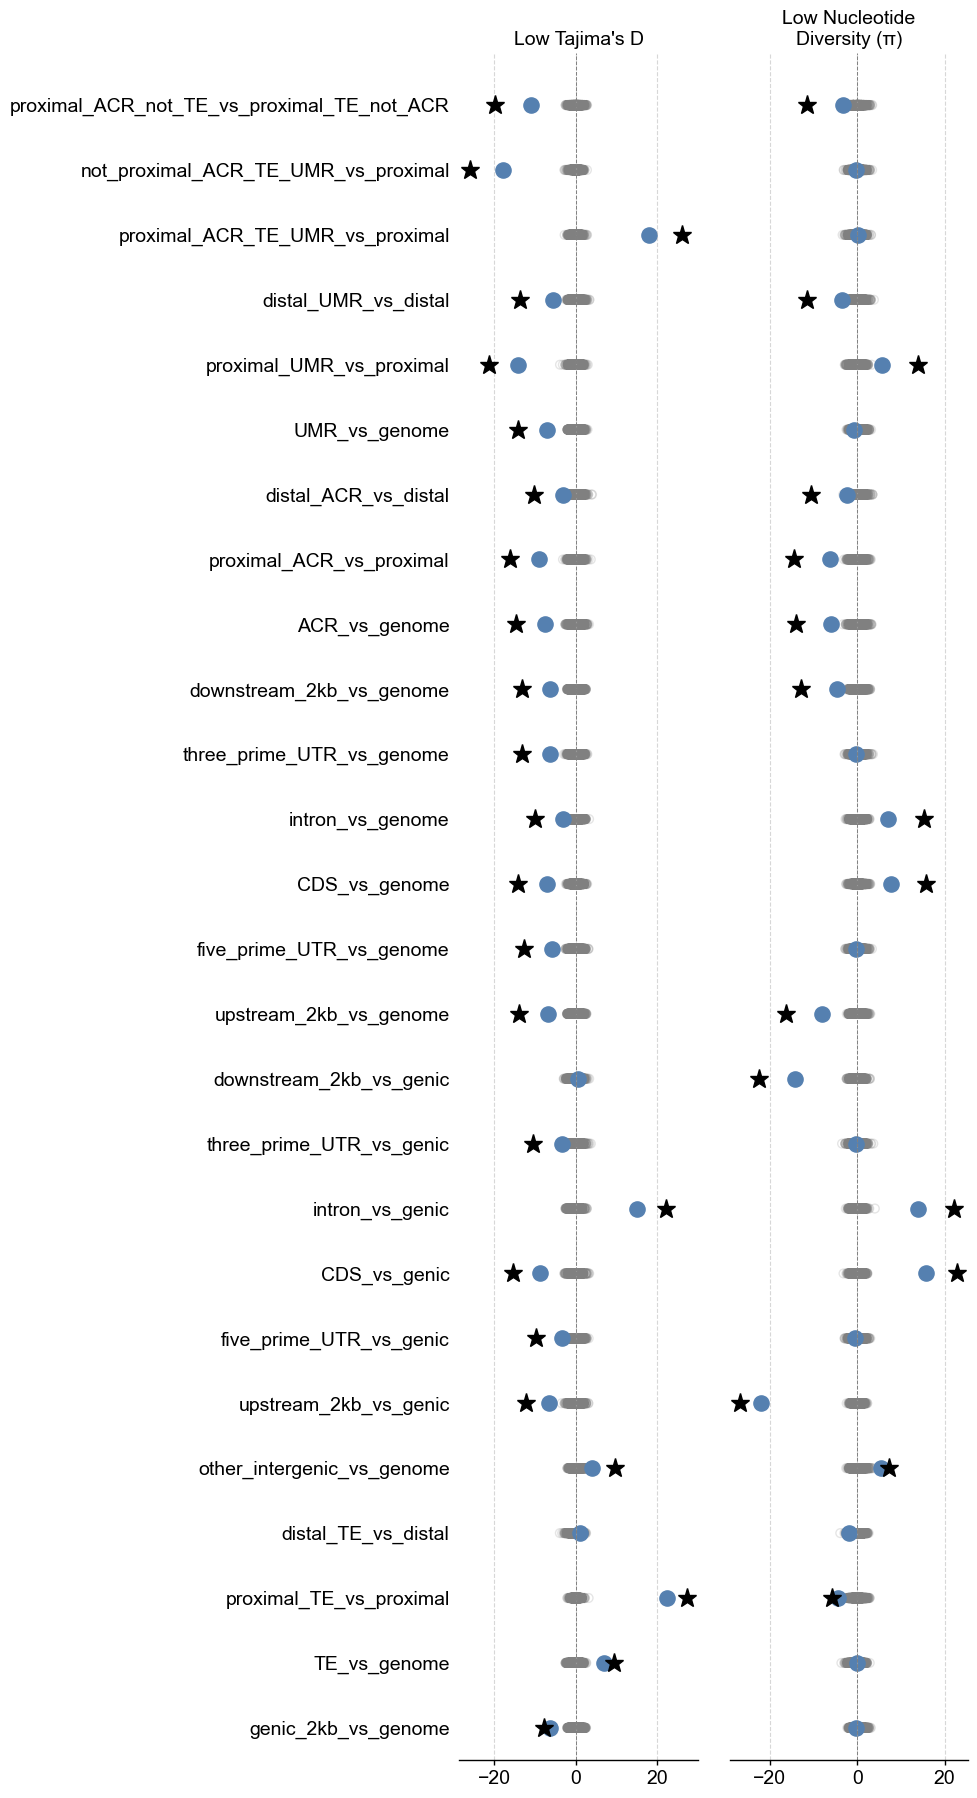

In [33]:
from src.enrich import plot_set_enrichment
import gzip

set_results_json = {}
for contrast_id, results_json_file in results_json_files.items():
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

set_label_map = [[contrast_id, contrast_id] for contrast_id in contrast_ids]
trait_metadata_df = pd.DataFrame([{"env_id": "TajimaD", "description": "Low Tajima's D"}, 
                                  {"env_id": "PI", "description": "Low Nucleotide Diversity (π)"}])

fig, axs = plot_set_enrichment(set_results_json, trait_id_list, trait_metadata_df, set_label_map, significance_threshold=0.05, height_per_set=0.7)

In [49]:
cs_enrich_dir = os.path.join(enrich_dir, "consistent_selection_site")
os.makedirs(cs_enrich_dir, exist_ok=True)

In [50]:
contrast_ids = ['genic_2kb_vs_genome',
 'TE_vs_genome',
 'proximal_TE_vs_proximal',
 'distal_TE_vs_distal',
 'other_intergenic_vs_genome',
 'upstream_2kb_vs_genic',
 'five_prime_UTR_vs_genic',
 'CDS_vs_genic',
 'intron_vs_genic',
 'three_prime_UTR_vs_genic',
 'downstream_2kb_vs_genic',
 'upstream_2kb_vs_genome',
 'five_prime_UTR_vs_genome',
 'CDS_vs_genome',
 'intron_vs_genome',
 'three_prime_UTR_vs_genome',
 'downstream_2kb_vs_genome',
 'missense_vs_CDS',
 'synonymous_vs_CDS',
 'putative_LoF_vs_CDS',
 'putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05',
 'ACR_vs_genome',
 'proximal_ACR_vs_proximal',
 'distal_ACR_vs_distal',
 'UMR_vs_genome',
 'proximal_UMR_vs_proximal',
 'distal_UMR_vs_distal',
 'riboSNitch_vs_gene_body',
 'proximal_ACR_TE_UMR_vs_proximal',
 'not_proximal_ACR_TE_UMR_vs_proximal',
 'proximal_ACR_not_TE_vs_proximal_TE_not_ACR',
 'low_pi',
 'med_pi',
 'high_pi',
 'non_CEs',
 'conserved_sites',
 'neutral_sites',
 'accelerated_sites',
]

In [51]:
import json
import gzip

datasets = {
    'genome': pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.genome.maf0.05.h5"), key="df"), # All variants with MAF >= 0.05
    'cds': pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.cds.maf0.01.h5"), key="df"), # All variants in coding regions with MAF >= 0.01
}

datasets['genome']['genome'] = True
datasets['cds']['cds'] = True

contexts_settings_json_file = os.path.join(os.getcwd(), "config", "contexts_settings.json")
with open(contexts_settings_json_file, "r") as f:
    contexts_settings = json.load(f)

trait_id_list = ['MAF']    

In [52]:
from src.enrich import site_jaccard_contrast_runner

results_json_files = {}
for contrast_id in contrast_ids:

    contrast_json = contrasts_settings[contrast_id]
    contrast_json['target'] = 'foreground'
    contrast_json

    contexts_df = build_enrich_data_df(datasets[contrast_json['dataset']], contrast_json, trait_id_list, other_columns=[])
    quant = 0.05

    for trait_id in trait_id_list:
        lower_quantile = np.quantile(contexts_df[trait_id].dropna(), quant)
        nonnan_mask = contexts_df[trait_id].notna()
        contexts_df.loc[nonnan_mask & (contexts_df[trait_id] <= lower_quantile), f'{trait_id}_lower_quantile'] = True
        contexts_df.loc[nonnan_mask & (contexts_df[trait_id] > lower_quantile), f'{trait_id}_lower_quantile'] = False
        contexts_df.drop(columns=[f'{trait_id}'], inplace=True)
        contexts_df.rename(columns={f'{trait_id}_lower_quantile': f'{trait_id}'}, inplace=True)

    output_dir = f'{cs_enrich_dir}/{contrast_id}'
    os.makedirs(output_dir, exist_ok=True)

    results_json_file = site_jaccard_contrast_runner(contrast_id, contrast_json, contexts_df, trait_id_list, output_dir, permutations=1000)
    results_json_files[contrast_id] = results_json_file

genic_2kb_vs_genome / MAF: 6452578/6452578 sites retained; 2277703 target, 361102 trait sites
TE_vs_genome / MAF: 6452578/6452578 sites retained; 3736514 target, 361102 trait sites
proximal_TE_vs_proximal / MAF: 3077170/3077170 sites retained; 1019295 target, 169457 trait sites
distal_TE_vs_distal / MAF: 3375408/3375408 sites retained; 2717219 target, 187091 trait sites
other_intergenic_vs_genome / MAF: 6452578/6452578 sites retained; 1054970 target, 361102 trait sites
Enrichment results already exist for contrast upstream_2kb_vs_genic, skipping.
five_prime_UTR_vs_genic / MAF: 2277703/2277703 sites retained; 87769 target, 121244 trait sites
CDS_vs_genic / MAF: 2277703/2277703 sites retained; 240922 target, 121244 trait sites
intron_vs_genic / MAF: 2277703/2277703 sites retained; 520464 target, 121244 trait sites
three_prime_UTR_vs_genic / MAF: 2277703/2277703 sites retained; 155961 target, 121244 trait sites
downstream_2kb_vs_genic / MAF: 2277703/2277703 sites retained; 755968 target, 

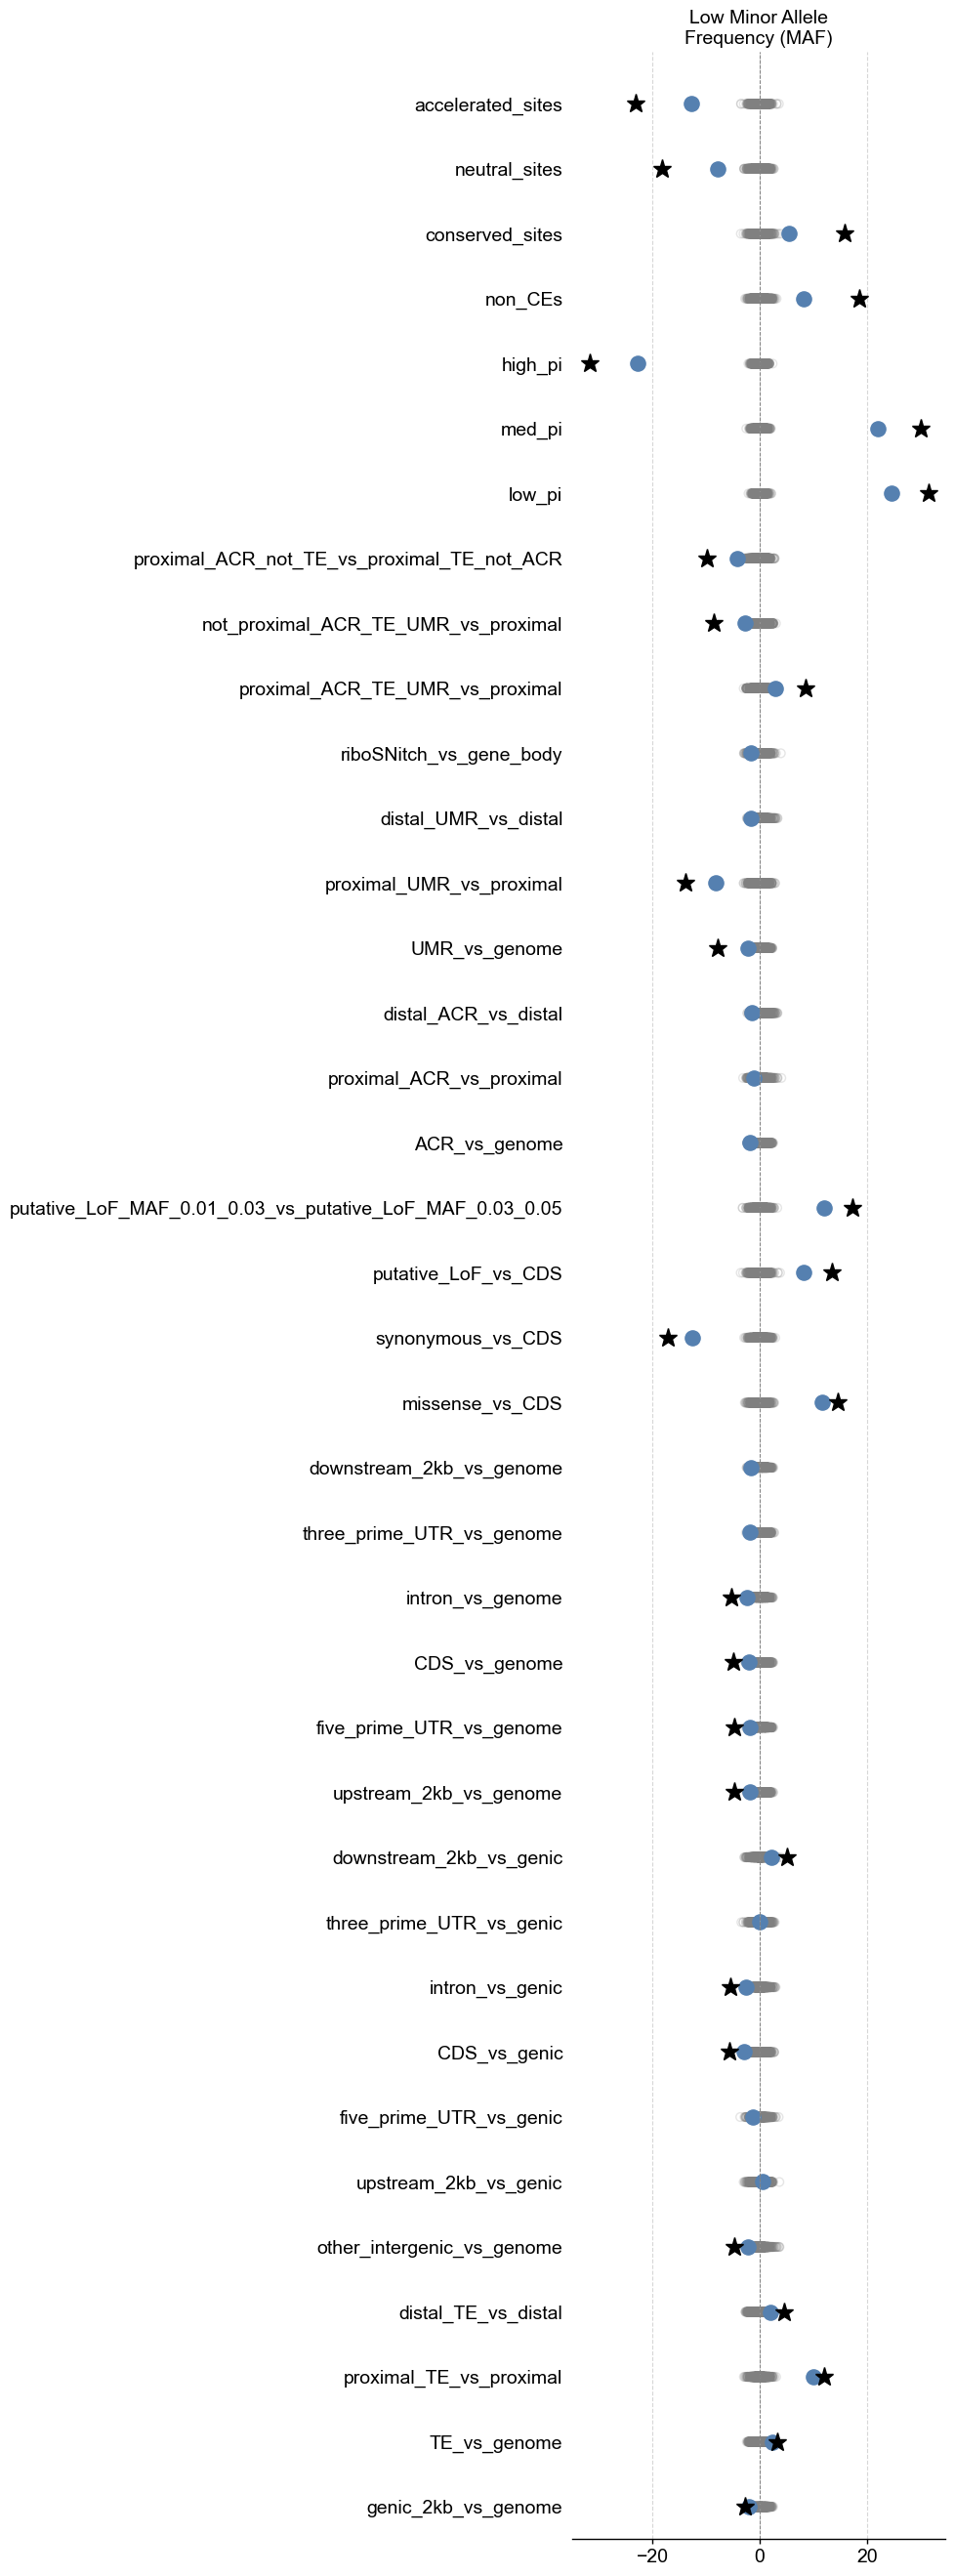

In [54]:
from src.enrich import plot_set_enrichment
import gzip

set_results_json = {}
for contrast_id, results_json_file in results_json_files.items():
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

set_label_map = [[contrast_id, contrast_id] for contrast_id in contrast_ids]
trait_metadata_df = pd.DataFrame([{"env_id": "MAF", "description": "Low Minor Allele Frequency (MAF)"}])

fig, axs = plot_set_enrichment(set_results_json, trait_id_list, trait_metadata_df, set_label_map, significance_threshold=0.05, height_per_set=0.7)